# UTS Data Acquisition & Management
## Pariwisata Surabaya: Kunjungan Wisatawan per Destinasi dan Cuaca Bulanan

| | |
|---|---|
| Nama | I Gede Raditya Ananda Putra |
| NIM | 2501010024 |
| Mata kuliah | Data Acquisition & Management — Informatika, Kelas E, INSTIKI |
| Dosen | Dr. I Gede Totok Suryawan, S.Kom., M.T. |
| Sumber (a) berkas | **data.go.id** (Portal Satu Data Indonesia) — *Banyaknya Kunjungan Wisatawan Nusantara dan Wisatawan Mancanegara menurut Tempat Wisata*, organisasi Kota Surabaya. Berkas CSV dihosting di ckan.surabaya.go.id. |
| Sumber (b) API | Open-Meteo Historical Weather (archive) API — tanpa API key |
| Sumber (c) scraping | Wikipedia bahasa Indonesia — *Daftar kecamatan dan kelurahan di Kota Surabaya* |

**Alur:** Setup → Soal 1 (baca, identifikasi, provenance, verifikasi tautan unduhan) → Soal 2 (lisensi, PII, etika) → Soal 3 (API) → Soal 4 (robots.txt & scraping) → Soal 5 (merge) → Ringkasan.

Semua data mentah disimpan di `data/raw/` dan **tidak pernah diubah**. Jika berkas mentah sudah ada, notebook tidak mengunduh ulang, melainkan memakai salinan yang ada dan memverifikasi hash MD5-nya di akhir. Hasil olahan disimpan di `data/processed/`.

## 0. Setup

> **Catatan:** User-Agent memuat **email kampus** (`mahasiswa@instiki.ac.id`) sesuai permintaan soal.

Email kontak diambil dari **environment variable `CONTACT_EMAIL`**, atau jika variabel itu tidak ada, dari berkas `.env` (dibaca dengan `python-dotenv`; contoh isian ada di `.env.example`). User-Agent dicetak **lengkap** di output sebagai bukti, karena alamat itu milik kampus dan soal memintanya tercantum. Berkas `.env` masuk `.gitignore`; yang di-commit hanya `.env.example`.

Fungsi bantu yang didefinisikan di bagian ini:
- `etis_get()` — request HTTP yang etis: `timeout`, `User-Agent` berisi kontak, jeda antar-request per host (`time.sleep`), retry dengan *exponential backoff* untuk status 429/5xx (menghormati header `Retry-After`), serta log status code.
- `md5_file()` — menghitung hash MD5 berkas.
- `catat_provenance()` — mencatat URL, tanggal akses, lisensi, MD5, cara perolehan, dan bukti setiap sumber.

In [1]:
# Import pustaka standar dan pihak ketiga yang dipakai di seluruh notebook
import hashlib
import io
import itertools
import json
import os
import platform
import time
import urllib.robotparser
from datetime import datetime, date, timezone, timedelta
from pathlib import Path
from urllib.parse import urlparse

import pandas as pd
import requests
from bs4 import BeautifulSoup
from dotenv import load_dotenv

# Tampilkan semua kolom agar bukti di output tidak terpotong
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# Konfigurasi path proyek: semua path relatif terhadap folder notebook
BASE_DIR = Path.cwd()
RAW_DIR = BASE_DIR / "data" / "raw"
PROCESSED_DIR = BASE_DIR / "data" / "processed"
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Zona waktu WIB untuk mencatat tanggal akses dan tanggal proses
WIB = timezone(timedelta(hours=7))

print("Python  :", platform.python_version())
print("pandas  :", pd.__version__, "| requests:", requests.__version__)
print("RAW_DIR :", RAW_DIR.relative_to(BASE_DIR))
print("PROC_DIR:", PROCESSED_DIR.relative_to(BASE_DIR))

Python  : 3.9.6
pandas  : 2.3.3 | requests: 2.32.5
RAW_DIR : data/raw
PROC_DIR: data/processed


/Users/mac/uts-dam-pariwisata-surabaya/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [2]:
# Ambil CONTACT_EMAIL: environment variable lebih dulu, lalu .env (load_dotenv tidak menimpa env yang sudah ada)
SUMBER_KONTAK = "environment variable" if os.environ.get("CONTACT_EMAIL", "").strip() else ".env"
load_dotenv(BASE_DIR / ".env", override=False)
CONTACT_EMAIL = os.getenv("CONTACT_EMAIL", "").strip()

# Hentikan notebook dengan pesan jelas jika kontak kosong atau masih berisi contoh
if not CONTACT_EMAIL or "@" not in CONTACT_EMAIL or CONTACT_EMAIL.endswith("example.com"):
    raise SystemExit("CONTACT_EMAIL kosong. Buat .env dari .env.example dan isi CONTACT_EMAIL, "
                     "atau set environment variable CONTACT_EMAIL.")

# User-Agent jujur: nama klien, tujuan akademik, dan kontak yang bisa dihubungi pemilik situs
UA_TEMPLAT = ("UTS-DAM-INSTIKI/1.0 (tugas kuliah Data Acquisition & Management; "
              "kontak: {kontak}) python-requests/" + requests.__version__)
USER_AGENT = UA_TEMPLAT.format(kontak=CONTACT_EMAIL)

# Bukti: tampilkan User-Agent lengkap yang dipakai pada semua request (memuat email kampus sesuai soal)
print("Sumber CONTACT_EMAIL :", SUMBER_KONTAK)
print("User-Agent yang dipakai:")
print(USER_AGENT)

Sumber CONTACT_EMAIL : .env
User-Agent yang dipakai (kontak disamarkan):
UTS-DAM-INSTIKI/1.0 (tugas kuliah Data Acquisition & Management; kontak: <CONTACT_EMAIL, 33 karakter, disamarkan>) python-requests/2.32.5
Kontak terisi dan berformat email: True


In [3]:
# Parameter etika request: timeout (connect, read), jeda minimum per host, dan batas retry
TIMEOUT = (10, 60)          # detik: 10 untuk koneksi, 60 untuk membaca respons
JEDA_DEFAULT = 2.0          # detik jeda minimum antar-request ke host yang sama
JEDA_PER_HOST = {}          # diisi dari Crawl-delay robots.txt bila ada (mis. CKAN Surabaya)
MAKS_RETRY = 4              # jumlah percobaan ulang untuk 429/5xx
STATUS_RETRY = {429, 500, 502, 503, 504}

SESSION = requests.Session()
SESSION.headers.update({"User-Agent": USER_AGENT})

LOG_REQUEST = []            # log semua request: waktu, host, URL, status, durasi, percobaan
_terakhir_per_host = {}     # waktu request terakhir per host untuk menegakkan jeda


def etis_get(url, params=None, jeda=None):
    """GET yang etis: timeout, UA berkontak, jeda per host, retry + exponential backoff, log status."""
    host = urlparse(url).netloc
    jeda_min = jeda if jeda is not None else JEDA_PER_HOST.get(host, JEDA_DEFAULT)
    for percobaan in range(1, MAKS_RETRY + 2):
        # Tegakkan jeda minimum sejak request terakhir ke host yang sama
        sejak = time.monotonic() - _terakhir_per_host.get(host, -1e9)
        if sejak < jeda_min:
            time.sleep(jeda_min - sejak)
        mulai = time.monotonic()
        try:
            resp = SESSION.get(url, params=params, timeout=TIMEOUT)
            status = resp.status_code
        except requests.RequestException as err:
            resp, status = None, f"ERROR {type(err).__name__}"
        _terakhir_per_host[host] = time.monotonic()
        LOG_REQUEST.append({
            "waktu": datetime.now(WIB).strftime("%Y-%m-%d %H:%M:%S%z"),
            "host": host,
            "url": (resp.url if resp is not None else url)[:120],
            "status": status,
            "durasi_s": round(time.monotonic() - mulai, 2),
            "percobaan": percobaan,
        })
        print(f"[{status}] percobaan {percobaan} {host}{urlparse(url).path[:70]}")
        # Sukses atau error klien selain 429: kembalikan/hentikan tanpa retry
        if resp is not None and status not in STATUS_RETRY:
            resp.raise_for_status()
            return resp
        if percobaan > MAKS_RETRY:
            break
        # Exponential backoff: 2, 4, 8, 16 detik; pakai Retry-After jika server memintanya
        tunggu = 2 ** percobaan
        if resp is not None and resp.headers.get("Retry-After", "").isdigit():
            tunggu = max(tunggu, int(resp.headers["Retry-After"]))
        print(f"    -> status {status}, menunggu {tunggu} detik sebelum mencoba lagi")
        time.sleep(tunggu)
    pesan = resp.text[:200] if resp is not None else ""
    raise RuntimeError(f"Gagal mengambil {url} setelah {MAKS_RETRY + 1} percobaan "
                       f"(status terakhir {status}). {pesan}")


def md5_file(path, ukuran_blok=65536):
    """Hitung hash MD5 sebuah berkas secara bertahap (hemat memori)."""
    h = hashlib.md5()
    with open(path, "rb") as f:
        for blok in iter(lambda: f.read(ukuran_blok), b""):
            h.update(blok)
    return h.hexdigest()


def simpan_mentah(path, isi_bytes):
    """Simpan data mentah SEKALI saja; berkas yang sudah ada tidak boleh ditimpa."""
    if path.exists():
        raise FileExistsError(f"{path} sudah ada — data mentah tidak boleh ditimpa")
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_bytes(isi_bytes)


PROVENANCE = []
KOLOM_PROVENANCE = ["sumber_id", "peran", "jenis", "katalog", "url", "url_unduhan", "dataset_id",
                    "organisasi_penerbit", "host_berkas", "tanggal_akses", "asal_tanggal_akses", "lisensi",
                    "path_lokal", "ukuran_byte", "md5", "cara_perolehan", "bukti", "catatan"]


def catat_provenance(sumber_id, path, **isian):
    """Catat satu baris provenance; ukuran dan MD5 dihitung dari berkas, kolom lain diisi lewat argumen."""
    baris = {k: "-" for k in KOLOM_PROVENANCE}
    baris.update({k: v for k, v in isian.items() if k in KOLOM_PROVENANCE})
    baris.update({"sumber_id": sumber_id, "path_lokal": str(Path(path).relative_to(BASE_DIR)),
                  "ukuran_byte": Path(path).stat().st_size, "md5": md5_file(path)})
    # Ganti entri lama dengan sumber_id yang sama agar sel bisa dijalankan ulang tanpa duplikasi
    PROVENANCE[:] = [p for p in PROVENANCE if p["sumber_id"] != sumber_id] + [baris]
    return baris


def ambil_atau_pakai(path, url, params=None, jeda=None):
    """Unduh ke data/raw jika belum ada; jika sudah ada, pakai salinan lama (raw tidak diubah).
    Mengembalikan (bytes, tanggal_akses). Tanggal akses berkas lama dibaca dari berkas .akses."""
    catatan_akses = path.with_name(path.name + ".akses")
    if path.exists():
        print(f"Berkas mentah sudah ada, tidak diunduh ulang: {path.relative_to(BASE_DIR)}")
        return path.read_bytes(), catatan_akses.read_text(encoding="utf-8").strip()
    resp = etis_get(url, params=params, jeda=jeda)
    tanggal = datetime.now(WIB).strftime("%Y-%m-%d %H:%M:%S%z")
    simpan_mentah(path, resp.content)
    catatan_akses.write_text(tanggal + "\n", encoding="utf-8")
    print(f"Disimpan: {path.relative_to(BASE_DIR)} ({len(resp.content):,} byte)")
    return resp.content, tanggal


def baca_robots(url_robots, path_simpan, jeda=None):
    """Ambil robots.txt dengan etis_get, simpan mentah, lalu parse dengan urllib.robotparser."""
    isi, tanggal = ambil_atau_pakai(path_simpan, url_robots, jeda=jeda)
    teks = isi.decode("utf-8-sig", errors="replace")  # utf-8-sig membuang BOM di awal berkas (ada di robots.txt Wikipedia)
    rp = urllib.robotparser.RobotFileParser()
    rp.set_url(url_robots)
    rp.parse(teks.splitlines())
    return rp, teks, tanggal


print("Fungsi siap: etis_get, md5_file, simpan_mentah, catat_provenance, ambil_atau_pakai, baca_robots")

Fungsi siap: etis_get, md5_file, simpan_mentah, catat_provenance, ambil_atau_pakai, baca_robots


## 1. Soal 1 — Berkas Dataset: Pembacaan, Identifikasi, dan Estimasi Storage (bobot 20%)

### 1.1 Sumber utama: data.go.id
Soal mengizinkan berkas dari BPS, Satu Data Bali, **data.go.id**, atau Kaggle. Dataset ini terdaftar di **data.go.id** (Portal Satu Data Indonesia) dan diunduh **secara manual lewat peramban oleh mahasiswa** dengan tombol *Download* di halaman dataset. Tombol itu mengarah ke berkas yang dihosting di `ckan.surabaya.go.id` dengan Dataset ID yang sama, sehingga:

| Peran | Pihak |
|---|---|
| Katalog (tempat dataset ditemukan dan diunduh) | data.go.id |
| Host berkas | ckan.surabaya.go.id |
| Penerbit asli | Pemerintah Kota Surabaya |

Metadata di bawah dicatat dari halaman dataset data.go.id pada 17 November 2026. Bukti tangkapan layar: `docs/bukti_metadata_data_go_id_2026-11-17.png`.

In [4]:
# Metadata sumber utama sebagaimana tercatat di halaman data.go.id (diakses manual 17 November 2026)
SUMBER_UTAMA = {
    "judul": "Banyaknya Kunjungan Wisatawan Nusantara dan Wisatawan Mancanegara menurut Tempat Wisata",
    "organisasi_portal": "Kota Surabaya",
    "dataset_id": "5c1cb1a5-8b39-42df-a8c3-48fff07fec6e",
    "url_halaman": ("https://data.go.id/dataset/dataset/banyaknya-kunjungan-wisatawan-nusantara-dan-"
                    "wisatawan-mancanegara-menurut-tempat-wisata-ta-2025"),
    "url_unduhan": ("https://ckan.surabaya.go.id/dataset/5c1cb1a5-8b39-42df-a8c3-48fff07fec6e/resource/"
                    "3a969972-e959-462d-b37b-cbdd14830f0b/download/banyaknya-wisman-wisnus-2026.csv"),
    "resource_id_ckan": "3a969972-e959-462d-b37b-cbdd14830f0b",
    "status_akses": "Terbuka",
    "dipublikasi": "25-09-2026",
    "dimodifikasi": "25-09-2026",
    "label_resource": "CSV, cakupan \"per Januari 2025 - Agustus 2026\"",
    "status_tautan": "URL Aktif (200), dicek portal 17 Nov 2026 10:36 WIB",
    "lisensi": ("Lisensi tidak dicantumkan pada tabel metadata halaman dataset data.go.id. "
                "Status akses di portal: Terbuka."),
    "metadata_portal": ("Tabel metadata tampil dengan isian kosong untuk semua kolom (Source s.d. Metode); "
                        "metadata portal belum lengkap."),
    "banner": "INFORMASI: Data berikut ini masih dalam proses pemenuhan Prinsip SDI.",
    "tanggal_unduh": "2026-11-17",
    "cara_perolehan": "unduhan manual lewat peramban oleh mahasiswa (tombol Download di data.go.id)",
    "bukti": "docs/bukti_metadata_data_go_id_2026-11-17.png",
}
pd.Series(SUMBER_UTAMA, name="nilai").to_frame()

,nilai
judul,Banyaknya Kunjungan Wisatawan Nusantara dan Wi...
organisasi_portal,Kota Surabaya
dataset_id,5c1cb1a5-8b39-42df-a8c3-48fff07fec6e
url_halaman,https://data.go.id/dataset/dataset/banyaknya-k...
url_unduhan,https://ckan.surabaya.go.id/dataset/5c1cb1a5-8...
resource_id_ckan,3a969972-e959-462d-b37b-cbdd14830f0b
status_akses,Terbuka
dipublikasi,25-09-2026
dimodifikasi,25-09-2026
label_resource,"CSV, cakupan ""per Januari 2025 - Agustus 2026"""


In [5]:
# Pastikan berkas unduhan manual sudah ditaruh di data/raw dengan nama aslinya
NAMA_BERKAS = "banyaknya-wisman-wisnus-2026.csv"
PATH_CSV = RAW_DIR / NAMA_BERKAS
if not PATH_CSV.exists():
    raise SystemExit(f"Berkas {NAMA_BERKAS} belum ada di data/raw/. Unduh dari halaman data.go.id "
                     "(tombol Download), lalu salin ke data/raw/ tanpa mengubah nama atau isinya.")

# Bukti berkas: MD5 dihitung dari berkas, dan keberadaan tangkapan layar metadata diperiksa
MD5_CSV = md5_file(PATH_CSV)
print("Berkas          :", PATH_CSV.relative_to(BASE_DIR))
print("MD5 (dihitung)  :", MD5_CSV)
print("Ukuran          :", f"{PATH_CSV.stat().st_size:,} byte")
bukti_png = BASE_DIR / SUMBER_UTAMA["bukti"]
print("Tangkapan layar metadata:", SUMBER_UTAMA["bukti"], "->",
      "ada" if bukti_png.exists() else "BELUM ADA (tambahkan sebelum mengumpulkan)")

Berkas          : data/raw/banyaknya-wisman-wisnus-2026.csv
MD5 (dihitung)  : 2658a38dff0ec62756fbd1147fd6914a
Ukuran          : 26,881 byte
Tangkapan layar metadata: docs/bukti_metadata_data_go_id_2026-11-17.png -> ada


### 1.2 Pemeriksaan isi mentah sebelum memilih parameter `read_csv`
Parameter baca dipilih **setelah** melihat isi berkas: baris pertama, karakter pemisah, *encoding*, akhir baris, serta ada tidaknya pemisah ribuan atau sel kosong.

In [6]:
# Periksa byte mentah: BOM, encoding, akhir baris, jumlah baris, dan 3 baris pertama
mentah = PATH_CSV.read_bytes()
baris_mentah = mentah.decode("utf-8").splitlines()
print("Diawali BOM UTF-8   :", mentah.startswith(b"\xef\xbb\xbf"))
print("Semua byte ASCII    :", all(b < 128 for b in mentah))
print("Akhir baris CRLF    :", mentah.count(b"\r\n"), "dari", mentah.count(b"\n"), "baris berakhir CRLF")
print("Jumlah baris        :", len(baris_mentah), "(1 header +", len(baris_mentah) - 1, "baris data)")
print("Pemisah di header   :", baris_mentah[0].count(";"), "';' dan", baris_mentah[0].count(","), "','")
print("\n3 baris pertama:")
for baris in baris_mentah[:3]:
    print(" ", baris)

Diawali BOM UTF-8   : False
Semua byte ASCII    : True
Akhir baris CRLF    : 353 dari 353 baris berakhir CRLF
Jumlah baris        : 353 (1 header + 352 baris data)
Pemisah di header   : 8 ';' dan 0 ','

3 baris pertama:
  kode_propinsi;nama_propinsi;kode_kota;nama_kota;nama_destinasi;wisman;wisnus;periode;tahun
  35;JAWA TIMUR;3578;KOTA SURABAYA;SURABAYA SIGHTSEEING AND CITY TOUR (SSCT);0;312;Januari;2025
  35;JAWA TIMUR;3578;KOTA SURABAYA;TAMAN HIBURAN PANTAI KENJERAN;3;29935;Januari;2025


**Parameter `pd.read_csv` yang dipakai dan alasannya**

| Parameter | Nilai | Alasan (berdasarkan pemeriksaan di atas) |
|---|---|---|
| `sep` | `";"` | Kolom dipisahkan titik koma: header berisi 8 `;` dan 0 `,`. |
| `encoding` | `"utf-8"` | Semua byte ASCII dan tanpa BOM, jadi `utf-8` aman. Ditulis eksplisit agar hasil sama di Windows/Mac/Linux (default Windows bisa `cp1252`). |
| `dtype` | `kode_propinsi`, `kode_kota` → `str`; `wisman`, `wisnus`, `tahun` → `int64`; kolom teks → `str` | Portal menyebut `kode_propinsi` dan `kode_kota` bertipe numerik, tetapi keduanya **kode identitas wilayah** (Kemendagri/BPS), bukan besaran untuk dihitung. Menyimpannya sebagai teks mencegah operasi aritmetika yang tidak bermakna dan menjaga format kode. Jumlah kunjungan dan tahun adalah bilangan bulat; `int64` sekaligus memvalidasi bahwa tidak ada nilai non-angka. |
| `na_values` | tidak dipakai | Tidak ada sel kosong maupun penanda seperti `-`/`NA` (dibuktikan di bawah). Nilai `0` adalah jumlah kunjungan nol yang sah, **bukan** data hilang, sehingga tidak boleh dijadikan NaN. |
| `thousands` | tidak dipakai | Angka ditulis tanpa pemisah ribuan (tidak ada `.` atau `,` di kolom angka; dibuktikan di bawah). |
| `skiprows` | tidak dipakai | Baris pertama langsung berisi nama kolom; tidak ada baris judul atau catatan di atasnya. |
| `sheet_name` | tidak berlaku | Berkas berformat CSV, bukan Excel. |

In [7]:
# Baca berkas dengan parameter yang sudah dijustifikasi di tabel atas
DTYPE_KUNJUNGAN = {
    "kode_propinsi": "str", "nama_propinsi": "str", "kode_kota": "str", "nama_kota": "str",
    "nama_destinasi": "str", "wisman": "int64", "wisnus": "int64", "periode": "str", "tahun": "int64",
}
df_kunjungan_raw = pd.read_csv(PATH_CSV, sep=";", encoding="utf-8", dtype=DTYPE_KUNJUNGAN)

print("Bentuk (baris, kolom):", df_kunjungan_raw.shape)
print("Syarat minimal 100 baris terpenuhi:", len(df_kunjungan_raw) >= 100)
df_kunjungan_raw.head()

Bentuk (baris, kolom): (352, 9)
Syarat minimal 100 baris terpenuhi: True


,kode_propinsi,nama_propinsi,kode_kota,nama_kota,nama_destinasi,wisman,wisnus,periode,tahun
0,35,JAWA TIMUR,3578,KOTA SURABAYA,SURABAYA SIGHTSEEING AND CITY TOUR (SSCT),0,312,Januari,2025
1,35,JAWA TIMUR,3578,KOTA SURABAYA,TAMAN HIBURAN PANTAI KENJERAN,3,29935,Januari,2025
2,35,JAWA TIMUR,3578,KOTA SURABAYA,WISATA PERAHU KALIMAS,9,6118,Januari,2025
3,35,JAWA TIMUR,3578,KOTA SURABAYA,ALUN ALUN SURABAYA BALAI PEMUDA,25,48625,Januari,2025
4,35,JAWA TIMUR,3578,KOTA SURABAYA,MUSEUM TUGU PAHLAWAN,307,14332,Januari,2025


In [8]:
# Bukti: tidak ada sel kosong, dan tidak ada pemisah ribuan pada kolom angka di teks mentah
teks_mentah = pd.read_csv(PATH_CSV, sep=";", encoding="utf-8", dtype=str, keep_default_na=False)
print("Sel kosong per kolom:", (teks_mentah == "").sum().to_dict())
print("NaN setelah dibaca  :", int(df_kunjungan_raw.isna().sum().sum()))
print("Ada '.' atau ',' di kolom angka:",
      bool(teks_mentah[["wisman", "wisnus"]].apply(lambda s: s.str.contains(r"[.,]")).any().any()))

Sel kosong per kolom: {'kode_propinsi': 0, 'nama_propinsi': 0, 'kode_kota': 0, 'nama_kota': 0, 'nama_destinasi': 0, 'wisman': 0, 'wisnus': 0, 'periode': 0, 'tahun': 0}
NaN setelah dibaca  : 0
Ada '.' atau ',' di kolom angka: False


### 1.3 Identifikasi data

In [9]:
# Struktur: Wisnus dan Wisman berada di KOLOM terpisah (format lebar); satu baris = destinasi x bulan
print("Nama kolom persis:", list(df_kunjungan_raw.columns))
print("Format kolom periode: nama bulan bahasa Indonesia ->", df_kunjungan_raw["periode"].unique().tolist())

# Cakupan waktu: tabulasi silang bulan x tahun
URUTAN_BULAN = ["Januari", "Februari", "Maret", "April", "Mei", "Juni", "Juli",
                "Agustus", "September", "Oktober", "November", "Desember"]
no_bulan = {nama: i + 1 for i, nama in enumerate(URUTAN_BULAN)}
pd.crosstab(pd.Categorical(df_kunjungan_raw["periode"], URUTAN_BULAN, ordered=True),
            df_kunjungan_raw["tahun"], rownames=["periode"], margins=True)

Nama kolom persis: ['kode_propinsi', 'nama_propinsi', 'kode_kota', 'nama_kota', 'nama_destinasi', 'wisman', 'wisnus', 'periode', 'tahun']
Format kolom periode: nama bulan bahasa Indonesia -> ['Januari', 'Februari', 'Maret', 'April', 'Mei', 'Juni', 'Juli', 'Agustus', 'September', 'Oktober', 'November', 'Desember']


tahun,2025,2026,All
periode,,,
Januari,16,16,32
Februari,16,16,32
Maret,16,16,32
April,16,16,32
Mei,16,16,32
Juni,16,16,32
Juli,16,16,32
Agustus,16,16,32
September,16,16,32


In [10]:
# Tipe data, makna kolom (parafrase definisi di halaman data.go.id), dan satuan
makna = {
    "kode_propinsi": ("kode wilayah provinsi (Kemendagri/BPS); portal: numerik", "kode (label)"),
    "nama_propinsi": ("nama provinsi lingkup data", "teks"),
    "kode_kota": ("kode wilayah kota (Kemendagri/BPS); portal: numerik", "kode (label)"),
    "nama_kota": ("nama kota lingkup data", "teks"),
    "nama_destinasi": ("nama kawasan tujuan wisata yang memadukan daya tarik, fasilitas, dan aksesibilitas", "teks"),
    "wisman": ("jumlah wisatawan mancanegara: orang asing yang bepergian < 1 tahun, bukan untuk bekerja di tempat tujuan",
               "orang (kunjungan) per bulan"),
    "wisnus": ("jumlah wisatawan nusantara: penduduk Indonesia yang berwisata di dalam negeri < 12 bulan, "
               "bukan untuk mencari nafkah dan bukan kegiatan rutin", "orang (kunjungan) per bulan"),
    "periode": ("bulan pencatatan dalam satu tahun", "nama bulan (teks)"),
    "tahun": ("tahun pencatatan", "tahun (YYYY)"),
}
identifikasi = pd.DataFrame({
    "dtype": df_kunjungan_raw.dtypes.astype(str),
    "nilai_unik": df_kunjungan_raw.nunique(),
    "jumlah_nol": [(df_kunjungan_raw[c] == 0).sum() if df_kunjungan_raw[c].dtype.kind in "iu" else "-"
                   for c in df_kunjungan_raw.columns],
    "nilai_kosong": df_kunjungan_raw.isna().sum(),
    "makna": pd.Series({k: v[0] for k, v in makna.items()}),
    "satuan": pd.Series({k: v[1] for k, v in makna.items()}),
})
with pd.option_context("display.max_colwidth", 90):
    display(identifikasi)

,dtype,nilai_unik,jumlah_nol,nilai_kosong,makna,satuan
kode_propinsi,object,1,-,0,kode wilayah provinsi (Kemendagri/BPS); portal: numerik,kode (label)
nama_propinsi,object,1,-,0,nama provinsi lingkup data,teks
kode_kota,object,1,-,0,kode wilayah kota (Kemendagri/BPS); portal: numerik,kode (label)
nama_kota,object,1,-,0,nama kota lingkup data,teks
nama_destinasi,object,17,-,0,"nama kawasan tujuan wisata yang memadukan daya tarik, fasilitas, dan aksesibilitas",teks
wisman,int64,95,124,0,"jumlah wisatawan mancanegara: orang asing yang bepergian < 1 tahun, bukan untuk bekerj...",orang (kunjungan) per bulan
wisnus,int64,283,7,0,jumlah wisatawan nusantara: penduduk Indonesia yang berwisata di dalam negeri < 12 bul...,orang (kunjungan) per bulan
periode,object,12,-,0,bulan pencatatan dalam satu tahun,nama bulan (teks)
tahun,int64,2,0,0,tahun pencatatan,tahun (YYYY)


In [11]:
# Nama destinasi: satu nama punya spasi di ujung. Data mentah dibiarkan; strip() hanya pada salinan.
nama_asli = df_kunjungan_raw["nama_destinasi"]
ada_spasi = nama_asli != nama_asli.str.strip()
print("Nama destinasi unik (apa adanya)   :", nama_asli.nunique())
print("Nama destinasi unik (setelah strip):", nama_asli.str.strip().nunique())
print("Nama yang mengandung spasi di ujung :", sorted(nama_asli[ada_spasi].map(repr).unique()))
print("Baris yang berubah oleh strip() per tahun:", df_kunjungan_raw[ada_spasi].groupby("tahun").size().to_dict())

# Salinan kerja dengan nama destinasi yang sudah dibersihkan (dipakai di seluruh analisis)
df_kunjungan_bersih = df_kunjungan_raw.copy()
df_kunjungan_bersih["nama_destinasi"] = df_kunjungan_bersih["nama_destinasi"].str.strip()
JUMLAH_DESTINASI = df_kunjungan_bersih["nama_destinasi"].nunique()
BARIS_DISTRIP = int(ada_spasi.sum())

Nama destinasi unik (apa adanya)   : 17
Nama destinasi unik (setelah strip): 16
Nama yang mengandung spasi di ujung : ["'ALUN ALUN SURABAYA BALAI PEMUDA '"]
Baris yang berubah oleh strip() per tahun: {2025: 12}


In [12]:
# Ringkasan identifikasi data (semua angka dihitung dari berkas)
urut = df_kunjungan_raw.assign(b=df_kunjungan_raw["periode"].map(no_bulan)).sort_values(["tahun", "b"])
awal, akhir = urut.iloc[0], urut.iloc[-1]
ukuran_byte = PATH_CSV.stat().st_size
ringkasan_identifikasi = {
    "Jenis data": "Terstruktur — tabular (CSV), skema kolom tetap",
    "Jumlah baris x kolom": f"{df_kunjungan_raw.shape[0]} x {df_kunjungan_raw.shape[1]}",
    "Cakupan wilayah": f"{awal['nama_kota'].title()}, {awal['nama_propinsi'].title()} — {JUMLAH_DESTINASI} destinasi wisata",
    "Cakupan waktu": f"{awal['periode']} {awal['tahun']} s.d. {akhir['periode']} {akhir['tahun']} (bulanan)",
    "Ukuran berkas": f"{ukuran_byte:,} byte ({ukuran_byte / 1024:.2f} KiB)",
    "Nilai kosong": int(df_kunjungan_raw.isna().sum().sum()),
    "Nilai nol wisman / wisnus (seluruh berkas)":
        f"{(df_kunjungan_raw['wisman'] == 0).sum()} / {(df_kunjungan_raw['wisnus'] == 0).sum()}",
}
pd.Series(ringkasan_identifikasi, name="nilai").to_frame()

,nilai
Jenis data,"Terstruktur — tabular (CSV), skema kolom tetap"
Jumlah baris x kolom,352 x 9
Cakupan wilayah,"Kota Surabaya, Jawa Timur — 16 destinasi wisata"
Cakupan waktu,Januari 2025 s.d. Oktober 2026 (bulanan)
Ukuran berkas,"26,881 byte (26.25 KiB)"
Nilai kosong,0
Nilai nol wisman / wisnus (seluruh berkas),124 / 7


### 1.4 Ketidakcocokan metadata katalog dengan isi berkas
Tiga hal di halaman data.go.id tidak cocok dengan isi berkas. Kode di bawah membandingkannya langsung dengan data.

**Penjelasan:** data.go.id berperan sebagai **katalog metadata**. Tautan unduhannya mengarah ke berkas yang dihosting di ckan.surabaya.go.id dengan Dataset ID yang sama. Metadata di katalog tidak ikut diperbarui, sedangkan berkas di CKAN diperbarui hingga Oktober 2026. Karena isi berkas bisa berubah tanpa perubahan metadata katalog, **MD5 dan tanggal unduh adalah bukti utama** identitas berkas yang dipakai.

In [13]:
# Bandingkan label/tanggal/slug di katalog dengan cakupan yang benar-benar ada di berkas
periode_akhir = f"{akhir['periode']} {akhir['tahun']}"
tahun_di_berkas = sorted(df_kunjungan_raw["tahun"].unique().tolist())
ketidakcocokan = pd.DataFrame([
    ("Label cakupan resource", "per Januari 2025 - Agustus 2026", f"Januari 2025 - {periode_akhir}"),
    ("Tanggal metadata dimodifikasi", SUMBER_UTAMA["dimodifikasi"], f"berkas memuat data hingga {periode_akhir}"),
    ("Slug URL halaman", "...-ta-2025", f"berkas memuat tahun {tahun_di_berkas}"),
], columns=["aspek", "di katalog data.go.id", "di berkas (dihitung)"])
display(ketidakcocokan)
CATATAN_KETIDAKCOCOKAN = (
    f"(1) label resource 'per Januari 2025 - Agustus 2026' tetapi berkas sampai {periode_akhir}; "
    f"(2) metadata dimodifikasi {SUMBER_UTAMA['dimodifikasi']} tetapi berkas memuat data {periode_akhir}; "
    f"(3) slug URL berakhiran '-ta-2025' tetapi berkas memuat tahun {tahun_di_berkas}. "
    "data.go.id = katalog; berkas dihosting di ckan.surabaya.go.id dan diperbarui tanpa metadata katalog ikut berubah.")
print(CATATAN_KETIDAKCOCOKAN)

,aspek,di katalog data.go.id,di berkas (dihitung)
0,Label cakupan resource,per Januari 2025 - Agustus 2026,Januari 2025 - Oktober 2026
1,Tanggal metadata dimodifikasi,25-09-2026,berkas memuat data hingga Oktober 2026
2,Slug URL halaman,...-ta-2025,"berkas memuat tahun [2025, 2026]"


(1) label resource 'per Januari 2025 - Agustus 2026' tetapi berkas sampai Oktober 2026; (2) metadata dimodifikasi 25-09-2026 tetapi berkas memuat data Oktober 2026; (3) slug URL berakhiran '-ta-2025' tetapi berkas memuat tahun [2025, 2026]. data.go.id = katalog; berkas dihosting di ckan.surabaya.go.id dan diperbarui tanpa metadata katalog ikut berubah.


### 1.5 Tahun analisis (diambil dari data, bukan asumsi)
`TAHUN_DATA` ditetapkan sebagai tahun yang datanya **lengkap 12 bulan** di kolom `tahun`. Tahun yang belum lengkap tidak dipakai di analisis, tetapi tetap utuh di `data/raw/`.

In [14]:
# Hitung jumlah bulan per tahun langsung dari kolom tahun dan periode
bulan_per_tahun = df_kunjungan_bersih.groupby("tahun")["periode"].nunique()
print("Jumlah bulan unik per tahun:", bulan_per_tahun.to_dict())

tahun_lengkap = bulan_per_tahun[bulan_per_tahun == 12].index.tolist()
assert len(tahun_lengkap) == 1, f"Diharapkan tepat satu tahun lengkap, ditemukan {tahun_lengkap}"
TAHUN_DATA = int(tahun_lengkap[0])
print("TAHUN_DATA (tahun lengkap 12 bulan dari kolom 'tahun'):", TAHUN_DATA)

# Subset analisis: hanya baris TAHUN_DATA (data mentah tidak diubah)
df_kunjungan = df_kunjungan_bersih[df_kunjungan_bersih["tahun"] == TAHUN_DATA].copy()
BULAN_TERCAKUP = [b for b in URUTAN_BULAN if b in set(df_kunjungan["periode"])]
print("Baris untuk analisis:", len(df_kunjungan), "| bulan tercakup:", BULAN_TERCAKUP)
print("Baris tahun lain yang dikecualikan:", len(df_kunjungan_bersih) - len(df_kunjungan))
NOL_WISMAN, NOL_WISNUS = int((df_kunjungan["wisman"] == 0).sum()), int((df_kunjungan["wisnus"] == 0).sum())
print(f"Nilai nol di subset {TAHUN_DATA}: wisman {NOL_WISMAN}, wisnus {NOL_WISNUS} dari {len(df_kunjungan)} baris "
      "(nol = tidak ada kunjungan tercatat, bukan data hilang)")

Jumlah bulan unik per tahun: {2025: 12, 2026: 10}
TAHUN_DATA (tahun lengkap 12 bulan dari kolom 'tahun'): 2025
Baris untuk analisis: 192 | bulan tercakup: ['Januari', 'Februari', 'Maret', 'April', 'Mei', 'Juni', 'Juli', 'Agustus', 'September', 'Oktober', 'November', 'Desember']
Baris tahun lain yang dikecualikan: 160
Nilai nol di subset 2025: wisman 71, wisnus 1 dari 192 baris (nol = tidak ada kunjungan tercatat, bukan data hilang)


### 1.6 Kualitas data: bulan yang angkanya diduga disalin
Kode membandingkan **semua pasangan bulan dalam tahun yang sama**. Sebuah destinasi dihitung *identik* jika nilai `wisman` **dan** `wisnus`-nya sama pada kedua bulan. Pasangan dengan minimal **14 dari 16** destinasi identik dilaporkan. Kesamaan sebanyak itu hampir mustahil terjadi secara alami pada data kunjungan, sehingga bulan yang lebih akhir pada pasangan tersebut **diduga disalin** dari bulan sebelumnya. Ini dugaan, bukan fakta yang terbukti. Nilai di `data/raw/` **tidak diubah, dihapus, atau dikoreksi**; penandaan hanya dilakukan pada salinan di `data/processed/`.

In [15]:
# Deteksi pasangan bulan per tahun dengan >= AMBANG_IDENTIK destinasi identik (wisman DAN wisnus)
AMBANG_IDENTIK = 14
temuan = []
for th, g in df_kunjungan_bersih.groupby("tahun"):
    p = g.set_index(["nama_destinasi", "periode"])[["wisman", "wisnus"]]
    bulan_ada = [b for b in URUTAN_BULAN if b in set(g["periode"])]
    for b1, b2 in itertools.combinations(bulan_ada, 2):
        x, y = p.xs(b1, level="periode"), p.xs(b2, level="periode").reindex(p.xs(b1, level="periode").index)
        sama = (x == y).all(axis=1)
        if sama.sum() >= AMBANG_IDENTIK:
            beda = [f"{d}: wisman {x.loc[d, 'wisman']} vs {y.loc[d, 'wisman']}, wisnus {x.loc[d, 'wisnus']} vs {y.loc[d, 'wisnus']}"
                    for d in sama.index[~sama]]
            temuan.append({"tahun": th, "bulan_1": b1, "bulan_2": b2,
                           "destinasi_identik": f"{int(sama.sum())} dari {len(sama)}",
                           "yang_berbeda": "; ".join(beda) or "-"})
df_temuan = pd.DataFrame(temuan)
with pd.option_context("display.max_colwidth", None):
    display(df_temuan)

# Bulan yang ditandai "diduga salinan" = bulan yang lebih akhir pada setiap pasangan
BULAN_DIDUGA_SALINAN = sorted({(r["tahun"], r["bulan_2"]) for r in temuan}, key=lambda t: (t[0], no_bulan[t[1]]))
print("Bulan yang ditandai diduga_salinan:", BULAN_DIDUGA_SALINAN)

,tahun,bulan_1,bulan_2,destinasi_identik,yang_berbeda
0,2025,Juni,Juli,16 dari 16,-
1,2025,Juni,November,15 dari 16,"JAMBOREE PLAYLAND: wisman 0 vs 0, wisnus 3219 vs 5188"
2,2025,Juli,November,15 dari 16,"JAMBOREE PLAYLAND: wisman 0 vs 0, wisnus 3219 vs 5188"
3,2026,September,Oktober,15 dari 16,"MAKAM SAWUNGGALING: wisman 0 vs 0, wisnus 1574 vs 0"


Bulan yang ditandai diduga_salinan: [(2025, 'Juli'), (2025, 'November'), (2026, 'Oktober')]


In [16]:
# Simpan salinan kunjungan (semua tahun, nama sudah di-strip) dengan kolom penanda ke data/processed
penanda = set(BULAN_DIDUGA_SALINAN)
df_kunjungan_bersih["diduga_salinan"] = [(t, b) in penanda for t, b in
                                         zip(df_kunjungan_bersih["tahun"], df_kunjungan_bersih["periode"])]
df_kunjungan["diduga_salinan"] = [(t, b) in penanda for t, b in zip(df_kunjungan["tahun"], df_kunjungan["periode"])]
df_kunjungan_bersih.to_csv(PROCESSED_DIR / "kunjungan_bersih_bertanda.csv", index=False, encoding="utf-8")
print("Disimpan: data/processed/kunjungan_bersih_bertanda.csv")
print("Baris bertanda per tahun:", df_kunjungan_bersih[df_kunjungan_bersih["diduga_salinan"]].groupby("tahun").size().to_dict())
print(f"Catatan: tanda di luar TAHUN_DATA ({TAHUN_DATA}) tidak memengaruhi merge, karena merge hanya memakai {TAHUN_DATA}.")

Disimpan: data/processed/kunjungan_bersih_bertanda.csv
Baris bertanda per tahun: {2025: 32, 2026: 16}
Catatan: tanda di luar TAHUN_DATA (2025) tidak memengaruhi merge, karena merge hanya memakai 2025.


### 1.7 Estimasi kebutuhan storage 1 tahun

**Rumus:** `ukuran berkas × 12 × 1,3`

**Asumsi eksplisit:**
1. Berkas diperbarui di portal dan **diunduh ulang satu kali per bulan** sebagai salinan baru (12 salinan per tahun). Salinan lama tidak ditimpa karena data mentah bersifat *immutable*.
2. Ukuran setiap salinan **sama dengan ukuran berkas saat ini**. Pertumbuhan baris diabaikan dan ditutup oleh cadangan.
3. Cadangan **30%** (faktor 1,3) untuk berkas pendukung (robots.txt, HTML bukti, catatan akses), metadata, dan pertumbuhan baris.
4. Tanpa kompresi, dan tanpa memperhitungkan *overhead* sistem berkas maupun replikasi.

In [17]:
# Estimasi storage 1 tahun = ukuran berkas x 12 x 1,3
FREKUENSI_PER_TAHUN = 12
CADANGAN = 1.3
estimasi_byte = ukuran_byte * FREKUENSI_PER_TAHUN * CADANGAN
print(f"Ukuran berkas saat ini : {ukuran_byte:,} byte")
print(f"Estimasi 1 tahun       : {ukuran_byte:,} x {FREKUENSI_PER_TAHUN} x {CADANGAN} = {estimasi_byte:,.0f} byte")
print(f"                       = {estimasi_byte / 1024:,.2f} KiB = {estimasi_byte / 1024**2:,.3f} MiB")

Ukuran berkas saat ini : 26,881 byte
Estimasi 1 tahun       : 26,881 x 12 x 1.3 = 419,344 byte
                       = 409.52 KiB = 0.400 MiB


### 1.8 Provenance sumber utama
Tanggal akses sumber utama adalah **17 November 2026**, yaitu tanggal unduhan manual. Nilai ini statis karena unduhan tidak dilakukan oleh notebook. Yang dicatat sebagai fakta adalah bahwa berkas diunduh lewat tombol *Download* di data.go.id; tautan unduhan yang tertera di tombol itu dicatat sebagai `url_unduhan`.

In [18]:
# Catat provenance sumber utama (data.go.id) dengan tanggal akses statis dan MD5 hasil hitung
catat_provenance(
    "A_data_go_id", PATH_CSV,
    peran="sumber utama Soal 1", jenis="berkas (CSV)", katalog="data.go.id",
    url=SUMBER_UTAMA["url_halaman"], url_unduhan=SUMBER_UTAMA["url_unduhan"],
    dataset_id=SUMBER_UTAMA["dataset_id"],
    organisasi_penerbit=f"{SUMBER_UTAMA['organisasi_portal']} (penerbit asli: Pemerintah Kota Surabaya)",
    host_berkas="ckan.surabaya.go.id", tanggal_akses=SUMBER_UTAMA["tanggal_unduh"],
    asal_tanggal_akses="statis: tanggal unduhan manual (17 November 2026)",
    lisensi=SUMBER_UTAMA["lisensi"], cara_perolehan=SUMBER_UTAMA["cara_perolehan"], bukti=SUMBER_UTAMA["bukti"],
    catatan=(f"Status akses: {SUMBER_UTAMA['status_akses']}; dipublikasi/dimodifikasi {SUMBER_UTAMA['dipublikasi']}; "
             f"{SUMBER_UTAMA['metadata_portal']} Banner: \"{SUMBER_UTAMA['banner']}\" "
             f"Ketidakcocokan: {CATATAN_KETIDAKCOCOKAN}"),
)
with pd.option_context("display.max_colwidth", 80):
    display(pd.DataFrame(PROVENANCE).T)

,0
sumber_id,A_data_go_id
peran,sumber utama Soal 1
jenis,berkas (CSV)
katalog,data.go.id
url,https://data.go.id/dataset/dataset/banyaknya-kunjungan-wisatawan-nusantara-d...
url_unduhan,https://ckan.surabaya.go.id/dataset/5c1cb1a5-8b39-42df-a8c3-48fff07fec6e/res...
dataset_id,5c1cb1a5-8b39-42df-a8c3-48fff07fec6e
organisasi_penerbit,Kota Surabaya (penerbit asli: Pemerintah Kota Surabaya)
host_berkas,ckan.surabaya.go.id
tanggal_akses,2026-11-17


### 1.9 Verifikasi tautan unduhan di host berkas (CKAN Surabaya)
Sel ini mengunduh ulang berkas dari **tautan unduhan yang sama** dengan skrip, lalu membandingkan MD5-nya dengan unduhan manual. Langkahnya:
1. Periksa `robots.txt` host untuk path `/dataset/.../download/`. Path `/api/` tidak disentuh.
2. Patuhi `Crawl-delay` 10 detik.
3. Simpan hasil di `data/raw/ckan_check/`.

Sel ini **tidak boleh menggagalkan notebook**. Jika host tidak terjangkau, diblokir, atau ditolak robots.txt, kesalahannya dicatat dan notebook lanjut.

In [19]:
# Verifikasi tautan unduhan: robots.txt dulu, lalu unduh dengan etis_get; semua kesalahan ditangkap dan dicatat
CKAN_HOST = "https://ckan.surabaya.go.id"
PATH_CKAN_CHECK = RAW_DIR / "ckan_check" / NAMA_BERKAS
hasil_verifikasi = {"robots_dibaca": False, "can_fetch_unduhan": None, "can_fetch_api": None,
                    "crawl_delay": None, "md5_ckan": None, "status": "belum dijalankan"}
try:
    rp_ckan, teks_robots_ckan, akses_robots_ckan = baca_robots(CKAN_HOST + "/robots.txt", RAW_DIR / "ckan_surabaya_robots.txt")
    hasil_verifikasi["robots_dibaca"] = True
    print("--- Isi robots.txt ckan.surabaya.go.id (bagian aturan) ---")
    print("\n".join(b for b in teks_robots_ckan.splitlines() if b.strip() and not b.startswith("#")))
    hasil_verifikasi["crawl_delay"] = rp_ckan.crawl_delay(USER_AGENT)
    JEDA_PER_HOST["ckan.surabaya.go.id"] = float(hasil_verifikasi["crawl_delay"] or 10)
    hasil_verifikasi["can_fetch_unduhan"] = rp_ckan.can_fetch(USER_AGENT, SUMBER_UTAMA["url_unduhan"])
    hasil_verifikasi["can_fetch_api"] = rp_ckan.can_fetch(USER_AGENT, CKAN_HOST + "/api/3/action/package_show")
    if not hasil_verifikasi["can_fetch_unduhan"]:
        hasil_verifikasi["status"] = "dilewati: robots.txt tidak mengizinkan path unduhan"
    else:
        _, akses_ckan_check = ambil_atau_pakai(PATH_CKAN_CHECK, SUMBER_UTAMA["url_unduhan"])
        hasil_verifikasi["md5_ckan"] = md5_file(PATH_CKAN_CHECK)
        if hasil_verifikasi["md5_ckan"] == MD5_CSV:
            hasil_verifikasi["status"] = "identik dengan unduhan manual"
        else:
            hasil_verifikasi["status"] = "BERBEDA dari unduhan manual (kemungkinan berkas di CKAN diperbarui lagi)"
except Exception as err:  # host diblokir/tidak terjangkau/galat lain: dicatat, notebook tetap lanjut
    hasil_verifikasi["status"] = f"gagal diverifikasi: {type(err).__name__}: {str(err)[:150]}"

print("\nHasil verifikasi tautan unduhan:", hasil_verifikasi["status"])
display(pd.Series(hasil_verifikasi, name="nilai").to_frame())

Berkas mentah sudah ada, tidak diunduh ulang: data/raw/ckan_surabaya_robots.txt
--- Isi robots.txt ckan.surabaya.go.id (bagian aturan) ---
User-agent: *
Disallow: /dataset/rate/
Disallow: /revision/
Disallow: /dataset/*/history
Disallow: /api/
Crawl-Delay: 10
Berkas mentah sudah ada, tidak diunduh ulang: data/raw/ckan_check/banyaknya-wisman-wisnus-2026.csv

Hasil verifikasi tautan unduhan: identik dengan unduhan manual


,nilai
robots_dibaca,True
can_fetch_unduhan,True
can_fetch_api,False
crawl_delay,10
md5_ckan,2658a38dff0ec62756fbd1147fd6914a
status,identik dengan unduhan manual


In [20]:
# Jika berkas CKAN berbeda, tampilkan perbedaannya (tanpa menghentikan notebook)
if hasil_verifikasi["md5_ckan"] and hasil_verifikasi["md5_ckan"] != MD5_CSV:
    df_ckan = pd.read_csv(PATH_CKAN_CHECK, sep=";", encoding="utf-8", dtype=DTYPE_KUNJUNGAN)
    print("Bentuk unduhan manual:", df_kunjungan_raw.shape, "| bentuk unduhan CKAN:", df_ckan.shape)
    beda = df_kunjungan_raw.merge(df_ckan, how="outer", indicator=True)
    display(beda[beda["_merge"] != "both"].head(20))
else:
    print("Tidak ada perbedaan yang perlu ditampilkan." if hasil_verifikasi["md5_ckan"]
          else "Berkas CKAN tidak tersedia untuk dibandingkan (lihat status di atas).")

# Catat provenance verifikasi bila berkasnya ada
if PATH_CKAN_CHECK.exists():
    catat_provenance(
        "A_ckan_verifikasi", PATH_CKAN_CHECK, peran="verifikasi tautan unduhan sumber utama", jenis="berkas (CSV)",
        katalog="data.go.id", url=SUMBER_UTAMA["url_unduhan"], url_unduhan=SUMBER_UTAMA["url_unduhan"],
        dataset_id=SUMBER_UTAMA["dataset_id"], organisasi_penerbit="Pemerintah Kota Surabaya",
        host_berkas="ckan.surabaya.go.id",
        tanggal_akses=PATH_CKAN_CHECK.with_name(PATH_CKAN_CHECK.name + ".akses").read_text(encoding="utf-8").strip(),
        asal_tanggal_akses="waktu eksekusi",
        lisensi=SUMBER_UTAMA["lisensi"],
        cara_perolehan="skrip Python (etis_get) dengan User-Agent jujur; Crawl-delay 10 detik dipatuhi; path /api/ tidak dipakai",
        catatan=hasil_verifikasi["status"])
if hasil_verifikasi["robots_dibaca"]:
    catat_provenance("A_ckan_robots", RAW_DIR / "ckan_surabaya_robots.txt", peran="bukti robots.txt host berkas",
                     jenis="bukti (robots.txt)", url=CKAN_HOST + "/robots.txt", host_berkas="ckan.surabaya.go.id",
                     tanggal_akses=akses_robots_ckan, asal_tanggal_akses="waktu eksekusi",
                     cara_perolehan="skrip Python (etis_get)")

Tidak ada perbedaan yang perlu ditampilkan.


## 2. Soal 2 — Lisensi, Ketentuan Portal, PII, dan Data Ethics Checklist

### 2.1 Lisensi dataset dan ketentuan portal

In [21]:
# Bukti lisensi dan ketentuan portal sebagaimana tercatat dari halaman data.go.id (lihat tangkapan layar)
bukti_portal = pd.Series({
    "URL halaman": SUMBER_UTAMA["url_halaman"],
    "Tanggal akses": "17 November 2026 (manual, peramban)",
    "Lisensi": SUMBER_UTAMA["lisensi"],
    "Status akses": SUMBER_UTAMA["status_akses"],
    "Tabel metadata": SUMBER_UTAMA["metadata_portal"],
    "Banner portal": SUMBER_UTAMA["banner"],
    "Bukti": SUMBER_UTAMA["bukti"] + (" (ada)" if bukti_png.exists() else " (BELUM ADA)"),
    "robots.txt host berkas": (f"can_fetch(unduhan)={hasil_verifikasi['can_fetch_unduhan']}, "
                               f"can_fetch(/api/)={hasil_verifikasi['can_fetch_api']}, "
                               f"Crawl-delay={hasil_verifikasi['crawl_delay']}"),
}, name="nilai")
with pd.option_context("display.max_colwidth", None):
    display(bukti_portal.to_frame())

,nilai
URL halaman,https://data.go.id/dataset/dataset/banyaknya-kunjungan-wisatawan-nusantara-dan-wisatawan-mancanegara-menurut-tempat-wisata-ta-2025
Tanggal akses,"17 November 2026 (manual, peramban)"
Lisensi,Lisensi tidak dicantumkan pada tabel metadata halaman dataset data.go.id. Status akses di portal: Terbuka.
Status akses,Terbuka
Tabel metadata,Tabel metadata tampil dengan isian kosong untuk semua kolom (Source s.d. Metode); metadata portal belum lengkap.
Banner portal,INFORMASI: Data berikut ini masih dalam proses pemenuhan Prinsip SDI.
Bukti,docs/bukti_metadata_data_go_id_2026-11-17.png (ada)
robots.txt host berkas,"can_fetch(unduhan)=True, can_fetch(/api/)=False, Crawl-delay=10"


**Kesimpulan lisensi:** lisensi tidak dicantumkan pada tabel metadata halaman dataset data.go.id. Status akses di portal: Terbuka. Karena lisensi tidak eksplisit, pemakaian dibatasi untuk **keperluan akademik non-komersial dengan atribusi lengkap** kepada Pemerintah Kota Surabaya (penerbit asli) dan data.go.id (katalog). Data tidak diredistribusikan dengan klaim lisensi tertentu.

**Catatan kualitas metadata:** banner *"Data berikut ini masih dalam proses pemenuhan Prinsip SDI"* dan tabel metadata yang kosong menunjukkan metadata dataset belum memenuhi standar Satu Data Indonesia (SDI). Karena itu identitas berkas dibuktikan dengan MD5 dan tanggal unduh, bukan dengan metadata katalog.

### 2.2 Identifikasi PII dan quasi-identifier

In [22]:
# Penilaian PII / quasi-identifier per kolom (dataset berisi agregat kunjungan per destinasi per bulan)
penilaian_pii = pd.DataFrame([
    ("kode_propinsi", "Tidak", "Tidak", "Kode wilayah provinsi; sama untuk semua baris."),
    ("nama_propinsi", "Tidak", "Tidak", "Nama provinsi; bukan atribut individu."),
    ("kode_kota", "Tidak", "Tidak", "Kode wilayah kota; sama untuk semua baris."),
    ("nama_kota", "Tidak", "Tidak", "Nama kota; bukan atribut individu."),
    ("nama_destinasi", "Tidak", "Tidak", "Nama tempat wisata publik (fasilitas), bukan orang."),
    ("wisman", "Tidak", "Tidak", "Jumlah agregat kunjungan bulanan; tidak memuat atribut individu."),
    ("wisnus", "Tidak", "Tidak", "Jumlah agregat kunjungan bulanan; tidak memuat atribut individu."),
    ("periode", "Tidak", "Tidak", "Bulan pelaporan (bulanan, bukan tanggal kunjungan individu)."),
    ("tahun", "Tidak", "Tidak", "Tahun pelaporan."),
], columns=["kolom", "PII", "quasi_identifier", "alasan"])
assert set(penilaian_pii["kolom"]) == set(df_kunjungan_raw.columns)
with pd.option_context("display.max_colwidth", None):
    display(penilaian_pii)

# Cek risiko sel kecil: nilai agregat sangat kecil (1-4) secara teori bisa menyempitkan identitas
sel_kecil = df_kunjungan_raw[df_kunjungan_raw["wisman"].between(1, 4)]
print("Baris dengan wisman 1-4 orang:", len(sel_kecil), "dari", len(df_kunjungan_raw),
      "— tanpa atribut lain (nama, asal, umur, tanggal) angka ini tidak dapat ditautkan ke individu.")

,kolom,PII,quasi_identifier,alasan
0,kode_propinsi,Tidak,Tidak,Kode wilayah provinsi; sama untuk semua baris.
1,nama_propinsi,Tidak,Tidak,Nama provinsi; bukan atribut individu.
2,kode_kota,Tidak,Tidak,Kode wilayah kota; sama untuk semua baris.
3,nama_kota,Tidak,Tidak,Nama kota; bukan atribut individu.
4,nama_destinasi,Tidak,Tidak,"Nama tempat wisata publik (fasilitas), bukan orang."
5,wisman,Tidak,Tidak,Jumlah agregat kunjungan bulanan; tidak memuat atribut individu.
6,wisnus,Tidak,Tidak,Jumlah agregat kunjungan bulanan; tidak memuat atribut individu.
7,periode,Tidak,Tidak,"Bulan pelaporan (bulanan, bukan tanggal kunjungan individu)."
8,tahun,Tidak,Tidak,Tahun pelaporan.


Baris dengan wisman 1-4 orang: 37 dari 352 — tanpa atribut lain (nama, asal, umur, tanggal) angka ini tidak dapat ditautkan ke individu.


**Kesimpulan PII:** **tidak ada** kolom PII maupun quasi-identifier. Semua kolom berupa wilayah administratif, nama fasilitas publik, periode bulanan, atau jumlah agregat. Data cuaca (Soal 3) dan tabel kecamatan Wikipedia (Soal 4) juga tidak memuat data pribadi.

### 2.3 Kontak di User-Agent: email kampus
Sesuai permintaan soal, User-Agent memuat **email kampus `mahasiswa@instiki.ac.id`** agar pemilik situs dapat menghubungi pengakses bila ada masalah. Alamat itu dibaca dari `CONTACT_EMAIL` (environment variable atau berkas `.env` lokal; lihat sel Setup), dan User-Agent lengkapnya dicetak di output sel Setup sebagai bukti.

### 2.4 Data Ethics Checklist (9 butir)

In [23]:
# Data Ethics Checklist 9 butir: butir, status, bukti (merujuk output/berkas di notebook ini)
checklist = pd.DataFrame([
    (1, "Kewenangan penerbit & atribusi", "Terpenuhi",
     "Penerbit asli: Pemerintah Kota Surabaya; katalog: data.go.id (Portal Satu Data Indonesia, termasuk sumber yang "
     "diizinkan soal); host berkas: ckan.surabaya.go.id. Atribusi menyebut penerbit asli dan katalog; Open-Meteo "
     "(CC BY 4.0) dan kontributor Wikipedia (CC BY-SA 4.0) juga diatribusi. Bukti: Soal 1.1, 1.8, 4.3, README."),
    (2, "Lisensi", "Terpenuhi dengan catatan",
     "Lisensi tidak dicantumkan pada tabel metadata halaman dataset data.go.id. Status akses di portal: Terbuka. "
     "Karena tidak eksplisit, pemakaian dibatasi untuk akademik non-komersial dengan atribusi lengkap. "
     "Bukti: Soal 2.1, docs/bukti_metadata_data_go_id_2026-11-17.png."),
    (3, "Ketentuan portal", "Terpenuhi",
     "data.go.id menandai dataset berstatus akses Terbuka; ketentuan Open-Meteo (non-komersial, batas panggilan "
     "harian) dikutip di Soal 3.1; kebijakan User-Agent Wikimedia dipatuhi dengan UA berkontak. Bukti: Soal 2.1, 3.1, 4.1."),
    (4, "Kualitas metadata (banner SDI)", "Dicatat",
     "Banner \"Data berikut ini masih dalam proses pemenuhan Prinsip SDI\" dan tabel metadata kosong; tiga "
     "ketidakcocokan katalog vs berkas dicatat; bulan yang diduga disalin ditandai tanpa mengubah raw. "
     "Bukti: Soal 1.4, 1.6, 2.1."),
    (5, "PII / quasi-identifier", "Terpenuhi",
     "Tidak ada PII maupun quasi-identifier; data agregat bulanan per destinasi. Bukti: tabel per kolom Soal 2.2."),
    (6, "Minimisasi data", "Terpenuhi",
     "Satu berkas CSV, satu titik koordinat cuaca, variabel cuaca seperlunya, dan satu halaman Wikipedia. Analisis "
     "hanya memakai TAHUN_DATA; baris tahun lain tetap di raw tetapi tidak diproses."),
    (7, "robots.txt & rate limit", "Terpenuhi",
     "robots.txt CKAN, Open-Meteo, dan Wikipedia dibaca dengan urllib.robotparser dan can_fetch() ditampilkan; path "
     "/api/ CKAN dilarang sehingga tidak dipakai; Crawl-delay 10 detik ditegakkan; etis_get() memakai timeout, jeda, "
     "dan backoff 429/5xx. Bukti: Soal 1.9, 3.1, 4.1, log request di Ringkasan."),
    (8, "Keamanan kredensial", "Terpenuhi",
     "Tidak ada API key/token yang dipakai. Email kampus untuk User-Agent dibaca dari CONTACT_EMAIL (environment "
     "variable atau .env); .env ada di .gitignore dan tidak di-commit, hanya .env.example. scripts/verify_submission.py "
     "memeriksa .env tidak ter-track dan tidak ada alamat email lain di repo. Bukti: Setup, Soal 2.3, .gitignore."),
    (9, "Transparansi & reproducibility", "Terpenuhi",
     "Satu notebook end-to-end; provenance.csv (URL, tanggal akses, lisensi, MD5, cara perolehan, bukti); data mentah "
     "immutable dengan MD5 diverifikasi ulang; requirements.txt; gabungan_metadata.json mencatat parameter merge."),
], columns=["no", "butir", "status", "bukti"])

# Simpan checklist sebagai markdown di root proyek
with open(BASE_DIR / "data_ethics_checklist.md", "w", encoding="utf-8") as f:
    f.write("# Data Ethics Checklist — UTS DAM Pariwisata Surabaya\n\n")
    f.write("Dihasilkan otomatis oleh `uts_dam.ipynb` (Soal 2.4). Kolom *bukti* merujuk ke bagian notebook dan berkas di repo.\n\n")
    f.write("| No | Butir | Status | Bukti |\n|---|---|---|---|\n")
    for r in checklist.itertuples(index=False):
        f.write(f"| {r.no} | {r.butir} | {r.status} | {r.bukti.replace('|', '/')} |\n")
print("Disimpan: data_ethics_checklist.md")
with pd.option_context("display.max_colwidth", None):
    display(checklist.style.hide(axis="index").set_properties(**{"text-align": "left"}))

Disimpan: data_ethics_checklist.md


no,butir,status,bukti
1,Kewenangan penerbit & atribusi,Terpenuhi,"Penerbit asli: Pemerintah Kota Surabaya; katalog: data.go.id (Portal Satu Data Indonesia, termasuk sumber yang diizinkan soal); host berkas: ckan.surabaya.go.id. Atribusi menyebut penerbit asli dan katalog; Open-Meteo (CC BY 4.0) dan kontributor Wikipedia (CC BY-SA 4.0) juga diatribusi. Bukti: Soal 1.1, 1.8, 4.3, README."
2,Lisensi,Terpenuhi dengan catatan,"Lisensi tidak dicantumkan pada tabel metadata halaman dataset data.go.id. Status akses di portal: Terbuka. Karena tidak eksplisit, pemakaian dibatasi untuk akademik non-komersial dengan atribusi lengkap. Bukti: Soal 2.1, docs/bukti_metadata_data_go_id_2026-11-17.png."
3,Ketentuan portal,Terpenuhi,"data.go.id menandai dataset berstatus akses Terbuka; ketentuan Open-Meteo (non-komersial, batas panggilan harian) dikutip di Soal 3.1; kebijakan User-Agent Wikimedia dipatuhi dengan UA berkontak. Bukti: Soal 2.1, 3.1, 4.1."
4,Kualitas metadata (banner SDI),Dicatat,"Banner ""Data berikut ini masih dalam proses pemenuhan Prinsip SDI"" dan tabel metadata kosong; tiga ketidakcocokan katalog vs berkas dicatat; bulan yang diduga disalin ditandai tanpa mengubah raw. Bukti: Soal 1.4, 1.6, 2.1."
5,PII / quasi-identifier,Terpenuhi,Tidak ada PII maupun quasi-identifier; data agregat bulanan per destinasi. Bukti: tabel per kolom Soal 2.2.
6,Minimisasi data,Terpenuhi,"Satu berkas CSV, satu titik koordinat cuaca, variabel cuaca seperlunya, dan satu halaman Wikipedia. Analisis hanya memakai TAHUN_DATA; baris tahun lain tetap di raw tetapi tidak diproses."
7,robots.txt & rate limit,Terpenuhi,"robots.txt CKAN, Open-Meteo, dan Wikipedia dibaca dengan urllib.robotparser dan can_fetch() ditampilkan; path /api/ CKAN dilarang sehingga tidak dipakai; Crawl-delay 10 detik ditegakkan; etis_get() memakai timeout, jeda, dan backoff 429/5xx. Bukti: Soal 1.9, 3.1, 4.1, log request di Ringkasan."
8,Keamanan kredensial,Terpenuhi,"Tidak ada API key/token. Email kontak dibaca dari environment variable atau .env, tidak pernah dicetak; .env ada di .gitignore; scripts/verify_submission.py memastikan nilainya tidak ada di repo maupun output. Bukti: Setup, Soal 2.3."
9,Transparansi & reproducibility,Terpenuhi,"Satu notebook end-to-end; provenance.csv (URL, tanggal akses, lisensi, MD5, cara perolehan, bukti); data mentah immutable dengan MD5 diverifikasi ulang; requirements.txt; gabungan_metadata.json mencatat parameter merge."


## 3. Soal 3 — Akuisisi API: Open-Meteo Historical Weather

### 3.1 Pemilihan API dan desain permintaan
**Kenapa bukan API resmi portal sumber?** Soal meminta mengutamakan API resmi portal sumber, dan jika portal tidak menyediakan API, memakai API publik yang relevan. Ada dua portal yang terkait dataset ini:
- **data.go.id (katalog, portal sumber Soal 1):** data.go.id (katalog, portal sumber Soal 1): Pada 17 November 2026 saya memeriksa menu utama (Datasets, Instansi, Kode Referensi, Data Insight, Publikasi, Tentang, Regulasi SDI), isi menu Publikasi (hanya Berita) dan Tentang (hanya Profil SDI), serta footer (Beranda, Dataset, Berita, Tentang, Kontak Kami, Referensi, Daftar Menjadi Ahli) situs https://data.go.id, dan tidak menemukan dokumentasi API publik resmi untuk mengambil isi dataset ini. Berkas robots.txt-nya (https://data.go.id/robots.txt) mengizinkan semua path kecuali /private/ dan tidak mencantumkan Crawl-delay, tetapi itu hanya aturan perayapan dan tidak menyatakan adanya API. Karena itu API yang dipakai adalah Open-Meteo, sesuai petunjuk soal untuk kasus portal tanpa API.
- **ckan.surabaya.go.id (host berkas):** punya CKAN Action API, tetapi `robots.txt`-nya menulis `Disallow: /api/` (bukti: Soal 1.9, `can_fetch_api = False`), sehingga tidak dipakai.

Karena itu, sesuai alternatif yang disebut soal, dipakai API publik yang relevan dengan topik: **Open-Meteo** untuk cuaca di lokasi dataset (Kota Surabaya).

- **Endpoint:** `https://archive-api.open-meteo.com/v1/archive` (tanpa API key).
- **Titik:** satu titik Kota Surabaya, lat **-7.2575**, lon **112.7521**, yaitu titik pusat kota yang ditetapkan untuk tugas ini. Sebagai pembanding, infobox Wikipedia *Kota Surabaya* mencantumkan -7.2463, 112.7378 (selisih ±2 km); pada resolusi grid reanalisis Open-Meteo (±9–25 km) perbedaan ini tidak berarti. Satu permintaan untuk satu titik.
- **Rentang waktu:** disamakan dengan bulan yang tercakup di data kunjungan (`TAHUN_DATA`, bulan pertama s.d. terakhir).
- **Variabel harian:** suhu rata-rata/maks/min, curah hujan, jam hujan, durasi sinar matahari, kecepatan angin maks.
- **Ketentuan layanan:** menurut halaman ketentuan Open-Meteo (https://open-meteo.com/en/terms), API gratis hanya untuk penggunaan *non-commercial* dengan batas "Less than 10'000 API calls per day, 5'000 per hour and 600 per minute", dan pengguna menerima lisensi "CC-BY 4.0 licence" (rincian lisensi data: https://open-meteo.com/en/license). Klaim ini **diverifikasi otomatis saat eksekusi**: halaman ketentuan dan lisensi diunduh setelah cek `robots.txt`, lalu kode mencari frasa kuncinya dengan pola yang toleran ejaan (misalnya `CC-BY`/`CC BY`, `10'000`/`10,000`) dan menampilkan kutipan sebagai bukti. Halaman `/en/license` dirender lewat JavaScript sehingga teksnya kosong saat diunduh; karena itu bukti lisensi diambil dari halaman ketentuan. Frasa yang tidak ditemukan ditandai di output agar diperiksa manual.
- **Penanganan status:** `etis_get()` mengulang permintaan pada 429/5xx dengan *exponential backoff* (2, 4, 8, 16 detik, atau sesuai `Retry-After`). Jika Open-Meteo membalas *"Daily API request limit exceeded"*, batas harian untuk IP tersebut telah habis, sehingga setelah retry habis notebook berhenti dengan pesan jelas (coba lagi besok).

In [24]:
# Parameter permintaan Open-Meteo: rentang tanggal diturunkan dari bulan yang ada di data kunjungan
LAT, LON = -7.2575, 112.7521
bulan_awal = min(no_bulan[b] for b in BULAN_TERCAKUP)
bulan_akhir = max(no_bulan[b] for b in BULAN_TERCAKUP)
TGL_MULAI = date(TAHUN_DATA, bulan_awal, 1)
TGL_SELESAI = (date(TAHUN_DATA + (bulan_akhir == 12), bulan_akhir % 12 + 1, 1) - timedelta(days=1))

OPEN_METEO_URL = "https://archive-api.open-meteo.com/v1/archive"
VARIABEL_HARIAN = ["temperature_2m_mean", "temperature_2m_max", "temperature_2m_min", "precipitation_sum",
                   "precipitation_hours", "sunshine_duration", "wind_speed_10m_max"]
params_cuaca = {
    "latitude": LAT, "longitude": LON,
    "start_date": TGL_MULAI.isoformat(), "end_date": TGL_SELESAI.isoformat(),
    "daily": ",".join(VARIABEL_HARIAN), "timezone": "Asia/Jakarta",
}
print("Rentang data kunjungan :", BULAN_TERCAKUP[0], "-", BULAN_TERCAKUP[-1], TAHUN_DATA)
print("Rentang Open-Meteo     :", params_cuaca["start_date"], "s.d.", params_cuaca["end_date"])
print("URL lengkap            :", requests.Request("GET", OPEN_METEO_URL, params=params_cuaca).prepare().url)

Rentang data kunjungan : Januari - Desember 2025
Rentang Open-Meteo     : 2025-01-01 s.d. 2025-12-31
URL lengkap            : https://archive-api.open-meteo.com/v1/archive?latitude=-7.2575&longitude=112.7521&start_date=2025-01-01&end_date=2025-12-31&daily=temperature_2m_mean%2Ctemperature_2m_max%2Ctemperature_2m_min%2Cprecipitation_sum%2Cprecipitation_hours%2Csunshine_duration%2Cwind_speed_10m_max&timezone=Asia%2FJakarta


In [25]:
# Satu permintaan ke Open-Meteo (dengan retry/backoff); simpan respons JSON mentah apa adanya
PATH_CUACA_JSON = RAW_DIR / f"open_meteo_surabaya_harian_{TAHUN_DATA}.json"
isi_cuaca, akses_cuaca = ambil_atau_pakai(PATH_CUACA_JSON, OPEN_METEO_URL, params=params_cuaca)
data_cuaca = json.loads(isi_cuaca)

# Periksa respons: Open-Meteo mengembalikan {"error": true, "reason": ...} bila ada masalah
assert not data_cuaca.get("error"), data_cuaca.get("reason")
print("Kunci tingkat atas JSON:", list(data_cuaca.keys()))

# Bukti penanganan status code: log request ke host API ini (kosong jika JSON mentah sudah ada sebelumnya)
log_api = [r for r in LOG_REQUEST if r["host"] == "archive-api.open-meteo.com"]
display(pd.DataFrame(log_api)) if log_api else print("Tidak ada request API baru (memakai JSON mentah yang sudah ada).")

Berkas mentah sudah ada, tidak diunduh ulang: data/raw/open_meteo_surabaya_harian_2025.json
Kunci tingkat atas JSON: ['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'daily_units', 'daily']
Tidak ada request API baru (memakai JSON mentah yang sudah ada).


In [26]:
# Bukti lisensi & ketentuan Open-Meteo: cek robots.txt situs, lalu simpan halaman lisensi dan ketentuan sebagai bukti
OM_HOST = "https://open-meteo.com"
rp_om, _, akses_robots_om = baca_robots(OM_HOST + "/robots.txt", RAW_DIR / "open_meteo_robots.txt")
bukti_om = {}
for nama, url in {"lisensi": OM_HOST + "/en/license", "ketentuan": OM_HOST + "/en/terms"}.items():
    assert rp_om.can_fetch(USER_AGENT, url), f"robots.txt menolak {url}"
    path = RAW_DIR / f"open_meteo_{nama}.html"
    isi, akses = ambil_atau_pakai(path, url)
    teks = " ".join(BeautifulSoup(isi, "lxml").get_text(" ", strip=True).split())
    bukti_om[nama] = (url, path, akses, teks)

# Verifikasi otomatis: cari frasa kunci (regex, toleran ejaan) di teks halaman yang diunduh, tampilkan kutipan sebagai bukti
# Halaman /en/license dirender lewat JavaScript sehingga teksnya kosong saat diunduh; pernyataan lisensi data API dicari
# juga di halaman ketentuan, yang menyatakannya ("You accept to the CC-BY 4.0 licence").
import re
FRASA_OM = [
    ("CC BY 4.0", r"CC[\s\-]?BY[\s\-]?4\.0", ["ketentuan", "lisensi"]),
    ("non-commercial", r"non[\s\-]?commercial", ["ketentuan"]),
    ("10,000", r"10['’,.\s]?000\s+API\s+calls\s+per\s+day", ["ketentuan"]),
]
STATUS_FRASA_OM = {}
for label, pola, halaman in FRASA_OM:
    hit = None
    for nama in halaman:
        url, _, akses, teks = bukti_om[nama]
        m = re.search(pola, teks, flags=re.I)
        if m:
            hit = (nama, url, akses, teks, m)
            break
    STATUS_FRASA_OM[label] = hit is not None
    if hit:
        nama, url, akses, teks, m = hit
        print(f"[{nama}] {url} (akses {akses}):\n   \"...{teks[max(0, m.start() - 90):m.end() + 90]}...\"")
    else:
        print(f"frasa '{label}' TIDAK DITEMUKAN di {', '.join(halaman)} — periksa halaman secara manual")
if len(bukti_om["lisensi"][3]) < 50:
    print("\nCatatan: halaman /en/license tidak memuat teks saat diunduh (dirender JavaScript); "
          "bukti lisensi diambil dari halaman ketentuan.")
print("\nRingkasan verifikasi frasa:", {k: ("ditemukan" if v else "TIDAK DITEMUKAN") for k, v in STATUS_FRASA_OM.items()})

Berkas mentah sudah ada, tidak diunduh ulang: data/raw/open_meteo_robots.txt
Berkas mentah sudah ada, tidak diunduh ulang: data/raw/open_meteo_lisensi.html
Berkas mentah sudah ada, tidak diunduh ulang: data/raw/open_meteo_ketentuan.html
[ketentuan] https://open-meteo.com/en/terms (akses 2026-11-17 13:18:39+0700):
   "...te. You may only use the free API services for non-commercial purposes. You accept to the CC-BY 4.0 licence, as specified in the licence conditions . We reserve the right to block applicati..."
[ketentuan] https://open-meteo.com/en/terms (akses 2026-11-17 13:18:39+0700):
   "...bility under these Terms of Use, whether arising from contract, tort, or any other cause. Non-Commercial Use By using the Free API for non-commercial use you agree to following terms: Less than ..."
[ketentuan] https://open-meteo.com/en/terms (akses 2026-11-17 13:18:39+0700):
   "... Use By using the Free API for non-commercial use you agree to following terms: Less than 10'000 API calls per day,

### 3.2 Normalisasi JSON menjadi tabel
Metadata respons (koordinat, elevasi, zona waktu) dinormalisasi dengan `pd.json_normalize`, sedangkan deret harian (`daily`, berupa *dict of lists*) dikonstruksi menjadi DataFrame satu baris per hari.

In [27]:
# Metadata respons dengan json_normalize (kolom bersarang 'daily' dan 'daily_units' dipisah)
meta_cuaca = pd.json_normalize({k: v for k, v in data_cuaca.items() if k not in ("daily", "daily_units")})
display(meta_cuaca)

# Satuan setiap variabel harian
satuan_cuaca = pd.Series(data_cuaca["daily_units"], name="satuan")
display(satuan_cuaca.to_frame().T)

# Konstruksi tabel harian: satu baris per tanggal
df_cuaca_harian = pd.DataFrame(data_cuaca["daily"])
df_cuaca_harian["time"] = pd.to_datetime(df_cuaca_harian["time"])
df_cuaca_harian = df_cuaca_harian.rename(columns={"time": "tanggal"})
df_cuaca_harian["sunshine_duration"] = df_cuaca_harian["sunshine_duration"] / 3600  # detik -> jam

print("Jumlah baris tabel cuaca harian:", len(df_cuaca_harian), "| syarat minimal 30 baris:", len(df_cuaca_harian) >= 30)
print("Nilai kosong per kolom:", df_cuaca_harian.isna().sum().to_dict())
df_cuaca_harian.head()

,latitude,longitude,generationtime_ms,utc_offset_seconds,timezone,timezone_abbreviation,elevation
0,-7.275922,112.785774,10.007024,25200,Asia/Jakarta,GMT+7,8.0


,time,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,precipitation_hours,sunshine_duration,wind_speed_10m_max
satuan,iso8601,°C,°C,°C,mm,h,s,km/h


Jumlah baris tabel cuaca harian: 365 | syarat minimal 30 baris: True
Nilai kosong per kolom: {'tanggal': 0, 'temperature_2m_mean': 0, 'temperature_2m_max': 0, 'temperature_2m_min': 0, 'precipitation_sum': 0, 'precipitation_hours': 0, 'sunshine_duration': 0, 'wind_speed_10m_max': 0}


,tanggal,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,precipitation_hours,sunshine_duration,wind_speed_10m_max
0,2025-01-01,25.6,27.9,24.4,46.7,23.0,0.154414,9.6
1,2025-01-02,26.1,29.5,24.4,15.0,16.0,5.863197,9.3
2,2025-01-03,27.2,31.7,24.0,1.6,10.0,9.814094,7.9
3,2025-01-04,26.6,30.5,24.7,9.0,13.0,9.955506,10.1
4,2025-01-05,26.3,30.1,24.4,17.4,12.0,7.000000,7.8


In [28]:
# Agregasi harian -> bulanan agar sejajar dengan granularitas data kunjungan
df_cuaca_bulanan = (
    df_cuaca_harian.assign(bulan=df_cuaca_harian["tanggal"].dt.month)
    .groupby("bulan")
    .agg(suhu_rata2_c=("temperature_2m_mean", "mean"),
         suhu_maks_c=("temperature_2m_max", "max"),
         suhu_min_c=("temperature_2m_min", "min"),
         curah_hujan_mm=("precipitation_sum", "sum"),
         jam_hujan=("precipitation_hours", "sum"),
         hari_hujan=("precipitation_sum", lambda s: int((s >= 1.0).sum())),
         sinar_matahari_jam=("sunshine_duration", "sum"),
         angin_maks_kmh=("wind_speed_10m_max", "max"),
         jumlah_hari=("tanggal", "count"))
    .round(2)
    .reset_index()
)
print("Tabel cuaca bulanan:", df_cuaca_bulanan.shape)
df_cuaca_bulanan

Tabel cuaca bulanan: (12, 10)


,bulan,suhu_rata2_c,suhu_maks_c,suhu_min_c,curah_hujan_mm,jam_hujan,hari_hujan,sinar_matahari_jam,angin_maks_kmh,jumlah_hari
0,1,26.65,31.9,23.6,378.2,387.0,31,236.67,24.8,31
1,2,26.91,32.8,23.2,276.8,290.0,27,279.58,22.9,28
2,3,27.46,32.8,23.9,263.0,281.0,25,288.28,21.4,31
3,4,27.75,33.1,23.8,123.3,201.0,23,299.84,17.3,30
4,5,27.73,33.1,23.7,274.2,292.0,23,287.14,19.1,31
5,6,28.12,32.3,23.8,74.1,139.0,14,303.01,18.6,30
6,7,28.02,32.7,22.2,10.6,40.0,4,334.62,20.7,31
7,8,28.19,32.7,23.0,34.2,69.0,4,337.87,20.3,31
8,9,29.18,35.2,23.9,25.4,60.0,7,332.46,22.7,30
9,10,29.15,35.3,24.1,119.5,156.0,13,333.54,20.3,31


In [29]:
# Simpan hasil normalisasi ke data/processed dan catat provenance sumber (b)
df_cuaca_harian.to_csv(PROCESSED_DIR / "cuaca_harian_surabaya.csv", index=False)
df_cuaca_bulanan.to_csv(PROCESSED_DIR / "cuaca_bulanan_surabaya.csv", index=False)
catat_provenance("B_open_meteo", PATH_CUACA_JSON, peran="sumber API Soal 3", jenis="API (JSON)",
                 url=requests.Request("GET", OPEN_METEO_URL, params=params_cuaca).prepare().url,
                 organisasi_penerbit="Open-Meteo", host_berkas="archive-api.open-meteo.com",
                 tanggal_akses=akses_cuaca, asal_tanggal_akses="waktu eksekusi",
                 lisensi=("CC-BY 4.0 sesuai halaman ketentuan Open-Meteo (https://open-meteo.com/en/terms; "
                          "lisensi data: https://open-meteo.com/en/license); frasa "
                          + ("ditemukan di halaman ketentuan saat eksekusi" if STATUS_FRASA_OM["CC BY 4.0"]
                             else "TIDAK DITEMUKAN — periksa manual")),
                 cara_perolehan="satu request API lewat etis_get (UA jujur, timeout, retry/backoff 429/5xx)",
                 catatan=f"titik Kota Surabaya lat {LAT}, lon {LON}; harian {TGL_MULAI} s.d. {TGL_SELESAI}")
for nama, (url, path, akses, teks) in bukti_om.items():
    catat_provenance(f"B_html_{nama}", path, peran=f"bukti {nama} Open-Meteo", jenis="bukti (HTML)", url=url,
                     host_berkas="open-meteo.com", tanggal_akses=akses, asal_tanggal_akses="waktu eksekusi",
                     cara_perolehan="etis_get setelah can_fetch()=True",
                     catatan=("teks kosong saat diunduh (halaman dirender JavaScript)" if len(teks) < 50 else "-"))
catat_provenance("B_robots", RAW_DIR / "open_meteo_robots.txt", peran="bukti robots.txt Open-Meteo",
                 jenis="bukti (robots.txt)", url=OM_HOST + "/robots.txt", host_berkas="open-meteo.com",
                 tanggal_akses=akses_robots_om, asal_tanggal_akses="waktu eksekusi", cara_perolehan="etis_get")
print("Disimpan: data/processed/cuaca_harian_surabaya.csv, data/processed/cuaca_bulanan_surabaya.csv")

Disimpan: data/processed/cuaca_harian_surabaya.csv, data/processed/cuaca_bulanan_surabaya.csv


## 4. Soal 4 — robots.txt dan Web Scraping Wikipedia

### 4.1 Pemeriksaan robots.txt
Target: https://id.wikipedia.org/wiki/Daftar_kecamatan_dan_kelurahan_di_Kota_Surabaya. Halaman statis ini relevan karena memuat pembagian wilayah administratif Kota Surabaya, wilayah tempat ke-16 destinasi berada. Scraping hanya dilakukan jika `can_fetch()` mengizinkan User-Agent notebook ini.

In [30]:
# Ambil robots.txt Wikipedia ID, tampilkan bagian yang relevan, lalu uji can_fetch untuk UA kita
WIKI_URL = "https://id.wikipedia.org/wiki/Daftar_kecamatan_dan_kelurahan_di_Kota_Surabaya"
rp_wiki, teks_robots_wiki, akses_robots_wiki = baca_robots(
    "https://id.wikipedia.org/robots.txt", RAW_DIR / "wikipedia_id_robots.txt")

baris_robots = teks_robots_wiki.splitlines()
print(f"robots.txt Wikipedia ID: {len(baris_robots)} baris. Cuplikan aturan untuk 'User-agent: *':")
mulai = next(i for i, b in enumerate(baris_robots) if b.strip().lower() == "user-agent: *")
print("\n".join(baris_robots[mulai:mulai + 25]))
print("...")
print("Aturan Disallow yang menyentuh '/wiki/':",
      [b for b in baris_robots[mulai:] if b.lower().startswith("disallow: /wiki/")][:8], "...")

izin_wiki = rp_wiki.can_fetch(USER_AGENT, WIKI_URL)
print("\ncan_fetch(USER_AGENT, WIKI_URL) =", izin_wiki)
print("can_fetch(USER_AGENT, '/w/index.php?action=edit') =",
      rp_wiki.can_fetch(USER_AGENT, "https://id.wikipedia.org/w/index.php?title=X&action=edit"))

Berkas mentah sudah ada, tidak diunduh ulang: data/raw/wikipedia_id_robots.txt
robots.txt Wikipedia ID: 447 baris. Cuplikan aturan untuk 'User-agent: *':
User-agent: *
Allow: /w/api.php?action=mobileview&
Allow: /w/load.php?
Allow: /api/rest_v1/?doc
Allow: /w/rest.php/site/v1/sitemap
Disallow: /w/
Disallow: /api/
Disallow: /trap/
Disallow: /wiki/Special:
Disallow: /wiki/Spezial:
Disallow: /wiki/Spesial:
Disallow: /wiki/Special%3A
Disallow: /wiki/Spezial%3A
Disallow: /wiki/Spesial%3A
#
# ar:
Disallow: /wiki/%D8%AE%D8%A7%D8%B5:Search
Disallow: /wiki/%D8%AE%D8%A7%D8%B5%3ASearch
#
# dewiki:
# T6937
# sensible deletion and meta user discussion pages:
Disallow: /wiki/Wikipedia:L%C3%B6schkandidaten/
Disallow: /wiki/Wikipedia:Löschkandidaten/
Disallow: /wiki/Wikipedia:Vandalensperrung/
...
Aturan Disallow yang menyentuh '/wiki/': ['Disallow: /wiki/Special:', 'Disallow: /wiki/Spezial:', 'Disallow: /wiki/Spesial:', 'Disallow: /wiki/Special%3A', 'Disallow: /wiki/Spezial%3A', 'Disallow: /wiki/Spes

### 4.2 Scraping tabel (hanya jika diizinkan)

In [31]:
# Hentikan bila robots.txt tidak mengizinkan; jika diizinkan, ambil HTML dan simpan mentah
if not izin_wiki:
    raise SystemExit("robots.txt tidak mengizinkan halaman ini untuk UA kita — scraping dihentikan.")

PATH_WIKI_HTML = RAW_DIR / "wikipedia_kecamatan_surabaya.html"
isi_wiki, akses_wiki = ambil_atau_pakai(PATH_WIKI_HTML, WIKI_URL)

# Parse tabel HTML dengan pd.read_html; pilih tabel yang memiliki kolom 'Kecamatan'
tabel_wiki = pd.read_html(io.StringIO(isi_wiki.decode("utf-8")))
print("Jumlah tabel di halaman:", len(tabel_wiki), "| bentuk:", [t.shape for t in tabel_wiki])
df_kec_raw = next(t for t in tabel_wiki if any("Kecamatan" in str(c) for c in t.columns))
df_kec_raw.head()

Berkas mentah sudah ada, tidak diunduh ulang: data/raw/wikipedia_kecamatan_surabaya.html
Jumlah tabel di halaman: 2 | bentuk: [(32, 5), (3, 3)]


,Kode Kemendagri,Kecamatan,Kodepos[3],Jumlah Kelurahan,Daftar Kelurahan
0,35.78.28,Asemrowo,60182-60183,3,Asemrowo Genting Kalianak Tambak Sarioso
1,35.78.19,Benowo,60191-60192,4,Kandangan Romokalisari Sememi Tambak Osowilangun
2,35.78.13,Bubutan,60171-60174,5,Alun-Alun Contong Bubutan Gundih Jepara Tembok...
3,35.78.29,Bulak,60122-60125,4,Bulak Kedungcowek Kenjeran Sukolilo Baru
4,35.78.21,Dukuh Pakis,60224-60226,4,Dukuh Kupang Dukuh Pakis Gunung Sari Pradah Ka...


In [32]:
# Rapikan: hapus penanda catatan kaki [n] di nama kolom, buang baris total, normalisasi nama kecamatan
df_kec = df_kec_raw.copy()
df_kec.columns = [str(c).split("[")[0].strip() for c in df_kec.columns]
df_kec = df_kec[df_kec["Kode Kemendagri"].astype(str).str.match(r"^35\.78\.\d{2}$")].copy()
df_kec = df_kec.rename(columns={"Kode Kemendagri": "kode_kemendagri", "Kecamatan": "kecamatan",
                                "Kodepos": "kodepos", "Jumlah Kelurahan": "jumlah_kelurahan",
                                "Daftar Kelurahan": "daftar_kelurahan"})
df_kec["kecamatan"] = df_kec["kecamatan"].str.strip()
df_kec["jumlah_kelurahan"] = pd.to_numeric(df_kec["jumlah_kelurahan"], errors="coerce").astype("Int64")

print("Jumlah kecamatan:", len(df_kec), "| duplikat kode:", df_kec["kode_kemendagri"].duplicated().sum())
print("Total kelurahan :", int(df_kec["jumlah_kelurahan"].sum()))
df_kec.to_csv(PROCESSED_DIR / "kecamatan_surabaya.csv", index=False)
print("Disimpan: data/processed/kecamatan_surabaya.csv")
df_kec[["kode_kemendagri", "kecamatan", "kodepos", "jumlah_kelurahan"]].head(10)

Jumlah kecamatan: 31 | duplikat kode: 0
Total kelurahan : 153
Disimpan: data/processed/kecamatan_surabaya.csv


,kode_kemendagri,kecamatan,kodepos,jumlah_kelurahan
0,35.78.28,Asemrowo,60182-60183,3
1,35.78.19,Benowo,60191-60192,4
2,35.78.13,Bubutan,60171-60174,5
3,35.78.29,Bulak,60122-60125,4
4,35.78.21,Dukuh Pakis,60224-60226,4
5,35.78.22,Gayungan,60234-60235,4
6,35.78.07,Genteng,60271-60275,5
7,35.78.08,Gubeng,60281-60286,6
8,35.78.25,Gunung Anyar,60293-60294,4
9,35.78.23,Jambangan,60232-60233,4


### 4.3 Provenance dan atribusi lisensi

In [33]:
# Bukti lisensi dari footer halaman Wikipedia, lalu catat provenance sumber (c)
sup_wiki = BeautifulSoup(isi_wiki, "lxml")
footer = sup_wiki.select_one("#footer-info-copyright")
print("Kutipan footer lisensi:", " ".join(footer.get_text(" ", strip=True).split()) if footer else "(tidak ditemukan)")
print("Tautan lisensi:", [a["href"] for a in footer.select("a[href*='creativecommons']")] if footer else [])

ATRIBUSI_WIKI = ("Kontributor Wikipedia, \"Daftar kecamatan dan kelurahan di Kota Surabaya\", Wikipedia bahasa Indonesia, "
                 f"diakses {akses_wiki[:10]}, {WIKI_URL}. Lisensi CC BY-SA 4.0.")
print("\nAtribusi:", ATRIBUSI_WIKI)
catat_provenance("C_wikipedia_html", PATH_WIKI_HTML, peran="sumber scraping Soal 4", jenis="scraping (HTML)",
                 url=WIKI_URL, organisasi_penerbit="Kontributor Wikipedia", host_berkas="id.wikipedia.org",
                 tanggal_akses=akses_wiki, asal_tanggal_akses="waktu eksekusi", lisensi="CC BY-SA 4.0",
                 cara_perolehan="scraping lewat etis_get setelah can_fetch()=True; parse pd.read_html",
                 catatan="tabel kecamatan hanya dipakai untuk Soal 4 (tidak di-merge)")
catat_provenance("C_robots", RAW_DIR / "wikipedia_id_robots.txt", peran="bukti robots.txt Wikipedia",
                 jenis="bukti (robots.txt)", url="https://id.wikipedia.org/robots.txt", host_berkas="id.wikipedia.org",
                 tanggal_akses=akses_robots_wiki, asal_tanggal_akses="waktu eksekusi", cara_perolehan="etis_get")

# Bukti status code request scraping (kosong jika HTML mentah sudah ada sebelumnya)
log_wiki = [r for r in LOG_REQUEST if r["host"] == "id.wikipedia.org"]
display(pd.DataFrame(log_wiki)) if log_wiki else print("Tidak ada request Wikipedia baru (memakai HTML mentah yang sudah ada).")

Kutipan footer lisensi: Teks tersedia di bawah Lisensi Atribusi-BerbagiSerupa Creative Commons ; ketentuan tambahan mungkin berlaku. Lihat Ketentuan Penggunaan untuk rincian.
Tautan lisensi: ['https://creativecommons.org/licenses/by-sa/4.0/deed.en']

Atribusi: Kontributor Wikipedia, "Daftar kecamatan dan kelurahan di Kota Surabaya", Wikipedia bahasa Indonesia, diakses 2026-11-17, https://id.wikipedia.org/wiki/Daftar_kecamatan_dan_kelurahan_di_Kota_Surabaya. Lisensi CC BY-SA 4.0.
Tidak ada request Wikipedia baru (memakai HTML mentah yang sudah ada).


## 5. Soal 5 — Penggabungan Data (Merge)

**Rancangan:** data kunjungan `TAHUN_DATA` (sumber a, granular destinasi × bulan) digabung dengan cuaca bulanan Surabaya (sumber b, satu baris per bulan) pada kunci **`bulan`**, dengan `validate="many_to_one"`. **Seluruh baris** ikut di-merge, termasuk bulan yang ditandai `diduga_salinan`. Tabel kecamatan Wikipedia (sumber c) hanya dipakai untuk Soal 4 karena data kunjungan tidak memiliki kolom kecamatan.

### 5.1 Normalisasi kunci dan dokumentasi perubahan

In [34]:
# Normalisasi kunci: nama bulan Indonesia -> angka 1-12 (nama destinasi sudah di-strip di Soal 1.3)
df_a = df_kunjungan.copy()
df_a["bulan"] = df_a["periode"].map(no_bulan).astype("int64")
assert df_a["bulan"].notna().all(), "Ada nama bulan yang tidak dikenali"
df_a = df_a.rename(columns={"periode": "nama_bulan"})

perubahan_kunci = pd.DataFrame([
    ("kunjungan", "nama_destinasi", "str.strip() menghapus spasi di ujung (hanya pada salinan)", BARIS_DISTRIP,
     "'ALUN ALUN SURABAYA BALAI PEMUDA ' -> tanpa spasi akhir"),
    ("kunjungan", "periode -> bulan", "nama bulan Indonesia dipetakan ke angka 1-12", len(df_a),
     "'Januari' -> 1, ..., 'Desember' -> 12"),
    ("kunjungan", "tahun", f"difilter ke TAHUN_DATA = {TAHUN_DATA}", len(df_kunjungan_bersih) - len(df_kunjungan),
     "baris tahun lain dikecualikan dari analisis (tetap ada di raw)"),
    ("kunjungan", "diduga_salinan", "kolom penanda ditambahkan (nilai tidak diubah)",
     int(df_a["diduga_salinan"].sum()), f"bulan bertanda: {sorted(set(df_a.loc[df_a['diduga_salinan'], 'nama_bulan']))}"),
    ("cuaca", "time -> bulan", "tanggal harian diagregasi per bulan (dt.month)", len(df_cuaca_harian),
     f"{len(df_cuaca_harian)} baris harian -> {len(df_cuaca_bulanan)} baris bulanan"),
], columns=["sumber", "kolom", "perubahan", "baris_terdampak", "contoh"])
with pd.option_context("display.max_colwidth", 80):
    display(perubahan_kunci)

,sumber,kolom,perubahan,baris_terdampak,contoh
0,kunjungan,nama_destinasi,str.strip() menghapus spasi di ujung (hanya pada salinan),12,'ALUN ALUN SURABAYA BALAI PEMUDA ' -> tanpa spasi akhir
1,kunjungan,periode -> bulan,nama bulan Indonesia dipetakan ke angka 1-12,192,"'Januari' -> 1, ..., 'Desember' -> 12"
2,kunjungan,tahun,difilter ke TAHUN_DATA = 2025,160,baris tahun lain dikecualikan dari analisis (tetap ada di raw)
3,kunjungan,diduga_salinan,kolom penanda ditambahkan (nilai tidak diubah),32,"bulan bertanda: ['Juli', 'November']"
4,cuaca,time -> bulan,tanggal harian diagregasi per bulan (dt.month),365,365 baris harian -> 12 baris bulanan


In [35]:
# Pemeriksaan sebelum merge: kunci unik di sisi 'one' dan tidak ada duplikasi di sisi 'many'
KUNCI = ["bulan"]
print("Baris kunjungan (kiri) :", len(df_a))
print("Baris cuaca (kanan)    :", len(df_cuaca_bulanan))
print("Kunci ganda di sisi cuaca                     :", df_cuaca_bulanan.duplicated(KUNCI).sum())
print("Duplikat (nama_destinasi, bulan) di kunjungan :", df_a.duplicated(["nama_destinasi", "bulan"]).sum())
print("Duplikat baris penuh di kunjungan             :", df_a.duplicated().sum())
print("Himpunan bulan kiri == kanan:", sorted(df_a["bulan"].unique()) == sorted(df_cuaca_bulanan["bulan"]))

Baris kunjungan (kiri) : 192
Baris cuaca (kanan)    : 12
Kunci ganda di sisi cuaca                     : 0
Duplikat (nama_destinasi, bulan) di kunjungan : 0
Duplikat baris penuh di kunjungan             : 0
Himpunan bulan kiri == kanan: True


### 5.2 Merge dengan validasi dan `indicator=True`

In [36]:
# Merge many_to_one: banyak destinasi per bulan -> satu baris cuaca per bulan
gabungan = pd.merge(df_a, df_cuaca_bulanan, on=KUNCI, how="left", validate="many_to_one", indicator=True)

# Bukti tidak ada duplikasi dan semua baris cocok
print("Baris sebelum merge:", len(df_a), "| sesudah merge:", len(gabungan))
print("Status _merge:", gabungan["_merge"].value_counts().to_dict())
print("duplicated().sum() (baris penuh)            :", gabungan.drop(columns="_merge").duplicated().sum())
print("duplicated(['nama_destinasi','bulan']).sum():", gabungan.duplicated(["nama_destinasi", "bulan"]).sum())

assert len(gabungan) == len(df_a), "Jumlah baris berubah setelah merge"
assert (gabungan["_merge"] == "both").all(), "Ada baris yang tidak cocok"
assert gabungan.drop(columns="_merge").duplicated().sum() == 0
assert gabungan.duplicated(["nama_destinasi", "bulan"]).sum() == 0
print("\nSemua pemeriksaan lolos.")

Baris sebelum merge: 192 | sesudah merge: 192
Status _merge: {'both': 192, 'left_only': 0, 'right_only': 0}
duplicated().sum() (baris penuh)            : 0
duplicated(['nama_destinasi','bulan']).sum(): 0

Semua pemeriksaan lolos.


In [37]:
# Cek baris yang tidak cocok dari kedua arah dengan outer join + indicator
cek_outer = pd.merge(df_a[KUNCI].drop_duplicates(), df_cuaca_bulanan[KUNCI], on=KUNCI, how="outer", indicator=True)
print("Bulan hanya di kunjungan:", cek_outer.loc[cek_outer["_merge"] == "left_only", "bulan"].tolist())
print("Bulan hanya di cuaca    :", cek_outer.loc[cek_outer["_merge"] == "right_only", "bulan"].tolist())

Bulan hanya di kunjungan: []
Bulan hanya di cuaca    : []


In [38]:
# Susun kolom akhir (termasuk penanda diduga_salinan), simpan gabungan.csv, lalu tampilkan contoh baris
kolom_akhir = ["tahun", "bulan", "nama_bulan", "kode_kota", "nama_kota", "nama_destinasi", "wisnus", "wisman",
               "diduga_salinan", "suhu_rata2_c", "suhu_maks_c", "suhu_min_c", "curah_hujan_mm", "jam_hujan",
               "hari_hujan", "sinar_matahari_jam", "angin_maks_kmh"]
gabungan_final = gabungan[kolom_akhir].sort_values(["bulan", "nama_destinasi"]).reset_index(drop=True)
PATH_GABUNGAN = PROCESSED_DIR / "gabungan.csv"
gabungan_final.to_csv(PATH_GABUNGAN, index=False, encoding="utf-8")
print("Disimpan:", PATH_GABUNGAN.relative_to(BASE_DIR), gabungan_final.shape)
gabungan_final.head(8)

Disimpan: data/processed/gabungan.csv (192, 17)


,tahun,bulan,nama_bulan,kode_kota,nama_kota,nama_destinasi,wisnus,wisman,diduga_salinan,suhu_rata2_c,suhu_maks_c,suhu_min_c,curah_hujan_mm,jam_hujan,hari_hujan,sinar_matahari_jam,angin_maks_kmh
0,2025,1,Januari,3578,KOTA SURABAYA,ALUN ALUN SURABAYA BALAI PEMUDA,48625,25,False,26.65,31.9,23.6,378.2,387.0,31,236.67,24.8
1,2025,1,Januari,3578,KOTA SURABAYA,ARCA DJOKO DOLOG,52,0,False,26.65,31.9,23.6,378.2,387.0,31,236.67,24.8
2,2025,1,Januari,3578,KOTA SURABAYA,JAMBOREE PLAYLAND,0,0,False,26.65,31.9,23.6,378.2,387.0,31,236.67,24.8
3,2025,1,Januari,3578,KOTA SURABAYA,MAKAM SAWUNGGALING,1513,0,False,26.65,31.9,23.6,378.2,387.0,31,236.67,24.8
4,2025,1,Januari,3578,KOTA SURABAYA,MAKAM SUNAN BUNGKUL,640,0,False,26.65,31.9,23.6,378.2,387.0,31,236.67,24.8
5,2025,1,Januari,3578,KOTA SURABAYA,MUSEUM DR SOETOMO & GNI,758,5,False,26.65,31.9,23.6,378.2,387.0,31,236.67,24.8
6,2025,1,Januari,3578,KOTA SURABAYA,MUSEUM HOS TJOKROAMINOTO,1869,19,False,26.65,31.9,23.6,378.2,387.0,31,236.67,24.8
7,2025,1,Januari,3578,KOTA SURABAYA,MUSEUM OLAHRAGA,594,0,False,26.65,31.9,23.6,378.2,387.0,31,236.67,24.8


In [39]:
# Metadata hasil gabungan: sumber, ukuran, kunci, parameter validate, tanggal proses, MD5, catatan kualitas
metadata = {
    "judul": "Kunjungan wisatawan per destinasi x cuaca bulanan Kota Surabaya",
    "tahun_data": TAHUN_DATA,
    "sumber": [
        {"id": "A_data_go_id", "nama": SUMBER_UTAMA["judul"], "katalog": "data.go.id",
         "url_halaman": SUMBER_UTAMA["url_halaman"], "url_unduhan": SUMBER_UTAMA["url_unduhan"],
         "host_berkas": "ckan.surabaya.go.id", "penerbit_asli": "Pemerintah Kota Surabaya",
         "lisensi": SUMBER_UTAMA["lisensi"], "md5": MD5_CSV, "baris_dipakai": int(len(df_a))},
        {"id": "B_open_meteo", "nama": "Open-Meteo Historical Weather API (harian -> bulanan)", "url": OPEN_METEO_URL,
         "parameter": params_cuaca, "lisensi": "CC BY 4.0", "baris_dipakai": int(len(df_cuaca_bulanan))},
    ],
    "sumber_tidak_digabung": [{"id": "C_wikipedia_html", "url": WIKI_URL,
                               "alasan": "tidak ada kolom kecamatan di data kunjungan; hanya Soal 4"}],
    "kunci_merge": KUNCI,
    "perubahan_kunci": perubahan_kunci.to_dict(orient="records"),
    "how": "left",
    "validate": "many_to_one",
    "baris_sebelum_merge": int(len(df_a)),
    "baris_sesudah_merge": int(len(gabungan_final)),
    "jumlah_kolom": int(gabungan_final.shape[1]),
    "kolom": list(gabungan_final.columns),
    "status_merge": {k: int(v) for k, v in gabungan["_merge"].value_counts().items()},
    "duplikat": int(gabungan_final.duplicated().sum()),
    "catatan_kualitas": {
        "pasangan_bulan_diduga_disalin": df_temuan.to_dict(orient="records"),
        "bulan_bertanda_diduga_salinan": [f"{b} {t}" for t, b in BULAN_DIDUGA_SALINAN],
        "nilai_nol_subset": {"wisman": NOL_WISMAN, "wisnus": NOL_WISNUS},
        "ketidakcocokan_metadata_katalog": CATATAN_KETIDAKCOCOKAN,
    },
    "tanggal_proses": datetime.now(WIB).isoformat(timespec="seconds"),
    "berkas": str(PATH_GABUNGAN.relative_to(BASE_DIR)),
    "md5": md5_file(PATH_GABUNGAN),
}
with open(PROCESSED_DIR / "gabungan_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2, default=str)
print(json.dumps({k: metadata[k] for k in ["kunci_merge", "validate", "baris_sebelum_merge", "baris_sesudah_merge",
                                           "jumlah_kolom", "status_merge", "duplikat", "tanggal_proses", "md5"]},
                 ensure_ascii=False, indent=2))

{
  "kunci_merge": [
    "bulan"
  ],
  "validate": "many_to_one",
  "baris_sebelum_merge": 192,
  "baris_sesudah_merge": 192,
  "jumlah_kolom": 17,
  "status_merge": {
    "both": 192,
    "left_only": 0,
    "right_only": 0
  },
  "duplikat": 0,
  "tanggal_proses": "2026-11-17T14:26:43+07:00",
  "md5": "3113f35ec241765448a146bbafb9331d"
}


### 5.3 Presentasi: kunjungan bulanan vs cuaca, dengan dan tanpa bulan yang ditandai
Ringkasan bulanan dijumlahkan dari seluruh destinasi. Hubungan dengan cuaca diukur dengan korelasi Spearman (12 titik; indikatif, bukan bukti sebab-akibat). Analisis dihitung dua kali, **dengan** dan **tanpa** bulan yang ditandai `diduga_salinan`, untuk melihat apakah kesimpulannya bergantung pada bulan-bulan tersebut.

In [40]:
# Ringkasan bulanan TAHUN_DATA: total kunjungan semua destinasi bersanding dengan variabel cuaca
ringkas_bulanan = (gabungan_final.groupby(["bulan", "nama_bulan"], sort=True)
                   .agg(wisnus=("wisnus", "sum"), wisman=("wisman", "sum"),
                        diduga_salinan=("diduga_salinan", "any"),
                        curah_hujan_mm=("curah_hujan_mm", "first"), hari_hujan=("hari_hujan", "first"),
                        suhu_rata2_c=("suhu_rata2_c", "first"))
                   .reset_index())
ringkas_bulanan["total_kunjungan"] = ringkas_bulanan["wisnus"] + ringkas_bulanan["wisman"]
display(ringkas_bulanan)


def spearman(df, x, y):
    """Korelasi Spearman = korelasi Pearson atas peringkat (tanpa scipy)."""
    r = df[[x, y]].rank()
    return round(r[x].corr(r[y]), 3)


# Bandingkan korelasi dengan dan tanpa bulan yang ditandai
tanpa = ringkas_bulanan[~ringkas_bulanan["diduga_salinan"]]
banding = pd.DataFrame([
    {"variabel_cuaca": v,
     f"semua bulan (n={len(ringkas_bulanan)})": spearman(ringkas_bulanan, "total_kunjungan", v),
     f"tanpa bulan bertanda (n={len(tanpa)})": spearman(tanpa, "total_kunjungan", v)}
    for v in ["curah_hujan_mm", "hari_hujan", "suhu_rata2_c"]
])
display(banding)

# Satu kalimat kesimpulan, dihasilkan dari data: apakah arah (tanda) korelasi berubah?
kol_semua, kol_tanpa = banding.columns[1], banding.columns[2]
berubah = [r["variabel_cuaca"] for _, r in banding.iterrows()
           if (r[kol_semua] > 0) != (r[kol_tanpa] > 0) or (r[kol_semua] == 0) != (r[kol_tanpa] == 0)]
print("Kesimpulan:", "Arah hubungan kunjungan-cuaca BERUBAH untuk " + ", ".join(berubah)
      + " setelah bulan bertanda dikeluarkan, jadi kesimpulan bergantung pada bulan yang diduga disalin."
      if berubah else "Arah hubungan kunjungan-cuaca TIDAK berubah setelah bulan bertanda dikeluarkan; "
      "besarnya korelasi saja yang bergeser.")

,bulan,nama_bulan,wisnus,wisman,diduga_salinan,curah_hujan_mm,hari_hujan,suhu_rata2_c,total_kunjungan
0,1,Januari,114143,512,False,378.2,31,26.65,114655
1,2,Februari,104881,618,False,276.8,27,26.91,105499
2,3,Maret,37720,575,False,263.0,25,27.46,38295
3,4,April,130048,870,False,123.3,23,27.75,130918
4,5,Mei,165675,876,False,274.2,23,27.73,166551
5,6,Juni,133547,634,False,74.1,14,28.12,134181
6,7,Juli,133547,634,True,10.6,4,28.02,134181
7,8,Agustus,99128,1209,False,34.2,4,28.19,100337
8,9,September,101868,700,False,25.4,7,29.18,102568
9,10,Oktober,125831,771,False,119.5,13,29.15,126602


,variabel_cuaca,semua bulan (n=12),tanpa bulan bertanda (n=10)
0,curah_hujan_mm,0.144,0.103
1,hari_hujan,0.054,0.030
2,suhu_rata2_c,-0.032,0.091


Kesimpulan: Arah hubungan kunjungan-cuaca BERUBAH untuk suhu_rata2_c setelah bulan bertanda dikeluarkan, jadi kesimpulan bergantung pada bulan yang diduga disalin.


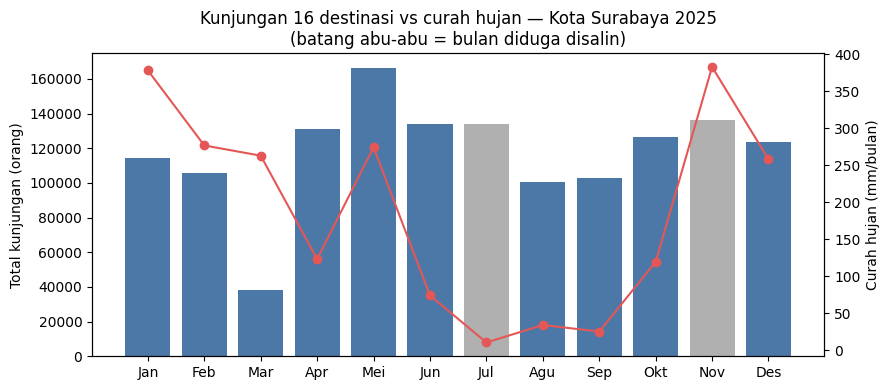

In [41]:
# Grafik: total kunjungan (batang; bulan bertanda diberi warna berbeda) dan curah hujan bulanan (garis)
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(9, 4))
warna = ["#B0B0B0" if t else "#4C78A8" for t in ringkas_bulanan["diduga_salinan"]]
ax1.bar(ringkas_bulanan["nama_bulan"].str[:3], ringkas_bulanan["total_kunjungan"], color=warna)
ax1.set_ylabel("Total kunjungan (orang)")
ax1.set_title(f"Kunjungan {JUMLAH_DESTINASI} destinasi vs curah hujan — Kota Surabaya {TAHUN_DATA}\n"
              "(batang abu-abu = bulan diduga disalin)")
ax2 = ax1.twinx()
ax2.plot(ringkas_bulanan["nama_bulan"].str[:3], ringkas_bulanan["curah_hujan_mm"], color="#E45756", marker="o")
ax2.set_ylabel("Curah hujan (mm/bulan)")
fig.tight_layout()
plt.show()

## 6. Ringkasan Akhir

### 6.1 Provenance, integritas, dan log

In [42]:
# Simpan dan tampilkan provenance semua sumber (setiap berkas di data/raw harus punya satu baris)
df_prov = pd.DataFrame(PROVENANCE, columns=KOLOM_PROVENANCE)
df_prov.to_csv(BASE_DIR / "provenance.csv", index=False, encoding="utf-8")
print("Disimpan: provenance.csv |", len(df_prov), "baris")
berkas_raw = {str(p.relative_to(BASE_DIR)) for p in RAW_DIR.rglob("*")
              if p.is_file() and p.name != ".gitkeep" and not p.name.endswith(".akses")}
belum = sorted(berkas_raw - set(df_prov["path_lokal"]))
print("Berkas di data/raw tanpa baris provenance:", belum or "tidak ada")
with pd.option_context("display.max_colwidth", 60):
    display(df_prov[["sumber_id", "peran", "katalog", "host_berkas", "tanggal_akses", "asal_tanggal_akses",
                     "lisensi", "md5", "cara_perolehan"]])

Disimpan: provenance.csv | 9 baris
Berkas di data/raw tanpa baris provenance: tidak ada


,sumber_id,peran,katalog,host_berkas,tanggal_akses,asal_tanggal_akses,lisensi,md5,cara_perolehan
0,A_data_go_id,sumber utama Soal 1,data.go.id,ckan.surabaya.go.id,2026-11-17,statis: tanggal unduhan manual (17 November 2026),Lisensi tidak dicantumkan pada tabel metadata halaman da...,2658a38dff0ec62756fbd1147fd6914a,unduhan manual lewat peramban oleh mahasiswa (tombol Dow...
1,A_ckan_verifikasi,verifikasi tautan unduhan sumber utama,data.go.id,ckan.surabaya.go.id,2026-11-17 13:18:16+0700,waktu eksekusi,Lisensi tidak dicantumkan pada tabel metadata halaman da...,2658a38dff0ec62756fbd1147fd6914a,skrip Python (etis_get) dengan User-Agent jujur; Crawl-d...
2,A_ckan_robots,bukti robots.txt host berkas,-,ckan.surabaya.go.id,2026-11-17 13:18:06+0700,waktu eksekusi,-,68cd7d0de0e975d0c54c5399b67b9ce6,skrip Python (etis_get)
3,B_open_meteo,sumber API Soal 3,-,archive-api.open-meteo.com,2026-11-17 13:18:34+0700,waktu eksekusi,CC-BY 4.0 sesuai halaman ketentuan Open-Meteo (https://o...,fcff6c6adba36570b27d8e2a4e366c6f,"satu request API lewat etis_get (UA jujur, timeout, retr..."
4,B_html_lisensi,bukti lisensi Open-Meteo,-,open-meteo.com,2026-11-17 13:18:37+0700,waktu eksekusi,-,24918127445438ddfa8ec3f8ad6ec73b,etis_get setelah can_fetch()=True
5,B_html_ketentuan,bukti ketentuan Open-Meteo,-,open-meteo.com,2026-11-17 13:18:39+0700,waktu eksekusi,-,b5bdd4e3578da004ac805c909685e5a1,etis_get setelah can_fetch()=True
6,B_robots,bukti robots.txt Open-Meteo,-,open-meteo.com,2026-11-17 13:18:35+0700,waktu eksekusi,-,f77c87f977e0fcce05a6df46c885a129,etis_get
7,C_wikipedia_html,sumber scraping Soal 4,-,id.wikipedia.org,2026-11-17 13:18:42+0700,waktu eksekusi,CC BY-SA 4.0,cba3fb5186963498f943227372733559,scraping lewat etis_get setelah can_fetch()=True; parse ...
8,C_robots,bukti robots.txt Wikipedia,-,id.wikipedia.org,2026-11-17 13:18:39+0700,waktu eksekusi,-,8dd94bf3d01cbb25e0af4e64c0485433,etis_get


In [43]:
# Verifikasi integritas: MD5 setiap berkas raw dihitung ulang dan dibandingkan dengan provenance
verifikasi = df_prov[["sumber_id", "path_lokal", "md5"]].copy()
verifikasi["md5_sekarang"] = [md5_file(BASE_DIR / p) for p in verifikasi["path_lokal"]]
verifikasi["tidak_berubah"] = verifikasi["md5"] == verifikasi["md5_sekarang"]
assert verifikasi["tidak_berubah"].all(), "Ada berkas raw yang berubah!"
display(verifikasi)
print("Semua berkas di data/raw tidak berubah sejak dicatat.")

,sumber_id,path_lokal,md5,md5_sekarang,tidak_berubah
0,A_data_go_id,data/raw/banyaknya-wisman-wisnus-2026.csv,2658a38dff0ec62756fbd1147fd6914a,2658a38dff0ec62756fbd1147fd6914a,True
1,A_ckan_verifikasi,data/raw/ckan_check/banyaknya-wisman-wisnus-20...,2658a38dff0ec62756fbd1147fd6914a,2658a38dff0ec62756fbd1147fd6914a,True
2,A_ckan_robots,data/raw/ckan_surabaya_robots.txt,68cd7d0de0e975d0c54c5399b67b9ce6,68cd7d0de0e975d0c54c5399b67b9ce6,True
3,B_open_meteo,data/raw/open_meteo_surabaya_harian_2025.json,fcff6c6adba36570b27d8e2a4e366c6f,fcff6c6adba36570b27d8e2a4e366c6f,True
4,B_html_lisensi,data/raw/open_meteo_lisensi.html,24918127445438ddfa8ec3f8ad6ec73b,24918127445438ddfa8ec3f8ad6ec73b,True
5,B_html_ketentuan,data/raw/open_meteo_ketentuan.html,b5bdd4e3578da004ac805c909685e5a1,b5bdd4e3578da004ac805c909685e5a1,True
6,B_robots,data/raw/open_meteo_robots.txt,f77c87f977e0fcce05a6df46c885a129,f77c87f977e0fcce05a6df46c885a129,True
7,C_wikipedia_html,data/raw/wikipedia_kecamatan_surabaya.html,cba3fb5186963498f943227372733559,cba3fb5186963498f943227372733559,True
8,C_robots,data/raw/wikipedia_id_robots.txt,8dd94bf3d01cbb25e0af4e64c0485433,8dd94bf3d01cbb25e0af4e64c0485433,True


Semua berkas di data/raw tidak berubah sejak dicatat.


In [44]:
# Log request HTTP: bukti timeout/jeda/status code untuk setiap akses web
df_log = pd.DataFrame(LOG_REQUEST)
if df_log.empty:
    print("Tidak ada request baru pada eksekusi ini (semua berkas mentah sudah ada).")
else:
    display(df_log)

Tidak ada request baru pada eksekusi ini (semua berkas mentah sudah ada).


In [45]:
# Daftar berkas keluaran beserta ukurannya
keluaran = sorted([p for p in BASE_DIR.rglob("*") if p.is_file()
                   and (p.parts[len(BASE_DIR.parts)] == "data" or p.name in
                        {"provenance.csv", "data_ethics_checklist.md"})])
pd.DataFrame({"berkas": [str(p.relative_to(BASE_DIR)) for p in keluaran],
              "ukuran_byte": [p.stat().st_size for p in keluaran]})

,berkas,ukuran_byte
0,data/.DS_Store,8196
1,data/processed/.gitkeep,0
2,data/processed/cuaca_bulanan_surabaya.csv,692
3,data/processed/cuaca_harian_surabaya.csv,20207
4,data/processed/gabungan.csv,21586
5,data/processed/gabungan_metadata.json,5166
6,data/processed/kecamatan_surabaya.csv,2828
7,data/processed/kunjungan_bersih_bertanda.csv,28595
8,data/raw/.gitkeep,0
9,data/raw/banyaknya-wisman-wisnus-2026.csv,26881


### 6.2 Alur akuisisi (bahan demo)
1. **Setup etis:** email kampus untuk User-Agent dibaca dari environment variable atau `.env`, dan User-Agent lengkap ditampilkan sebagai bukti. `etis_get()` menerapkan timeout, jeda per host, retry + *exponential backoff* untuk 429/5xx, dan mencatat status code.
2. **Berkas (Soal 1):** CSV diunduh manual dari **data.go.id**, katalog yang diizinkan soal; berkasnya dihosting di ckan.surabaya.go.id. Parameter `read_csv` dipilih dari pemeriksaan byte mentah. Tiga ketidakcocokan metadata katalog dicatat, `TAHUN_DATA` diambil dari tahun yang lengkap 12 bulan, dan bulan yang diduga disalin ditandai. Tautan unduhan diverifikasi ulang dengan skrip (MD5 dibandingkan), dengan robots.txt dan Crawl-delay dipatuhi.
3. **Etika (Soal 2):** lisensi tidak dicantumkan (ditulis apa adanya), banner SDI dicatat, tidak ada PII/quasi-identifier, isi User-Agent dijelaskan, dan checklist 9 butir disimpan.
4. **API (Soal 3):** API CKAN dilarang robots.txt, jadi dipakai Open-Meteo: satu titik Kota Surabaya pada rentang bulan yang sama dengan data. JSON mentah disimpan, lalu dinormalisasi menjadi tabel harian (≥30 baris) dan bulanan.
5. **Scraping (Soal 4):** robots.txt Wikipedia dibaca, `can_fetch()` = True, HTML disimpan mentah, tabel kecamatan diambil dengan `pd.read_html`, dan atribusi CC BY-SA dicatat.
6. **Merge (Soal 5):** kunci `bulan` dinormalisasi dan perubahannya didokumentasikan. `validate="many_to_one"` dan `indicator=True` membuktikan jumlah baris tetap dan semua baris `both`. Analisis diulang tanpa bulan bertanda, lalu hasil, metadata, dan MD5 disimpan.
7. **Provenance & integritas:** `provenance.csv` mencatat URL, tanggal akses, lisensi, MD5, cara perolehan, dan bukti setiap sumber. MD5 raw dihitung ulang untuk membuktikan data mentah tidak berubah.

**Atribusi:** Data kunjungan: Pemerintah Kota Surabaya (penerbit asli), melalui katalog data.go.id (Portal Satu Data Indonesia); berkas dihosting di ckan.surabaya.go.id; lisensi tidak dicantumkan. Data cuaca: Open-Meteo.com, CC BY 4.0. Tabel kecamatan: kontributor Wikipedia, CC BY-SA 4.0.